# USV 控制效果测试

本 Notebook 测试以下内容：
1. **USV 基本动力学控制** — 油门/舵角 → 轨迹、速度、航向响应
2. **不同控制输入的响应对比** — 直行、转弯、S 型机动
3. **洋流环境下的 USV 控制效果** — 无洋流 vs 有洋流对比
4. **洋流场可视化与影响分析**

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge
from shapely.geometry import Point, Polygon
import sys, os
import matplotlib

# 设置中文字体（解决中文乱码）
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'KaiTi', 'FangSong']
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题

# 确保导入路径
sys.path.insert(0, r'd:\fileForWhile\USV-MuilTarget-path-plaaning')
from USV import USV
from my_USV_Env import MyUsvEnv, ObstacleShape

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
print("导入成功 ✓")
print(f"当前字体: {plt.rcParams['font.sans-serif']}")

导入成功 ✓
当前字体: ['SimHei', 'Microsoft YaHei', 'KaiTi', 'FangSong']


## 1. USV 基本动力学响应测试

测试三种典型控制输入下的 USV 动力学响应：
- **直线加速**：油门 0.3，舵角 0°
- **恒定转弯**：油门 0.3，舵角 30°
- **S 型机动**：油门 0.3，舵角先 +30° 后 -30°

In [2]:
def simulate_usv(x0, y0, heading0, throttle_fn, rudder_fn, steps=300, dt=0.05):
    """
    通用仿真函数
    throttle_fn(t): 返回当前时刻的油门值
    rudder_fn(t):   返回当前时刻的舵角(弧度)
    """
    usv = USV(x=x0, y=y0, heading=heading0, mass=50.0, inertia=5.0, dt=dt)
    
    log = {
        'x': [], 'y': [], 'heading': [],
        'u': [], 'v': [], 'r': [],
        'throttle': [], 'rudder': [], 'time': []
    }
    
    for t in range(steps):
        throttle = throttle_fn(t)
        rudder = rudder_fn(t)
        
        usv.step(throttle, rudder)
        
        log['x'].append(usv.x)
        log['y'].append(usv.y)
        log['heading'].append(np.degrees(usv.heading))
        log['u'].append(usv.u)
        log['v'].append(usv.v)
        log['r'].append(usv.r)
        log['throttle'].append(throttle)
        log['rudder'].append(np.degrees(rudder))
        log['time'].append(t * dt)
    
    # 转换为 numpy 数组
    for k in log:
        log[k] = np.array(log[k])
    
    return usv, log

# ---- 场景1: 直线加速 ----
usv1, log1 = simulate_usv(0, 0, 0.0,
                           throttle_fn=lambda t: 0.3,
                           rudder_fn=lambda t: 0.0,
                           steps=300)

# ---- 场景2: 恒定转弯 ----
usv2, log2 = simulate_usv(0, 0, 0.0,
                           throttle_fn=lambda t: 0.3,
                           rudder_fn=lambda t: np.radians(30),
                           steps=300)

# ---- 场景3: S型机动 ----
usv3, log3 = simulate_usv(0, 0, 0.0,
                           throttle_fn=lambda t: 0.3,
                           rudder_fn=lambda t: np.radians(30) if t < 150 else np.radians(-30),
                           steps=300)

print("仿真完成 ✓")
print(f"  直线: 终点 ({log1['x'][-1]:.1f}, {log1['y'][-1]:.1f}), 最终速度 u={log1['u'][-1]:.2f} m/s")
print(f"  转弯: 终点 ({log2['x'][-1]:.1f}, {log2['y'][-1]:.1f}), 最终角速度 r={log2['r'][-1]:.3f} rad/s")
print(f"  S型:  终点 ({log3['x'][-1]:.1f}, {log3['y'][-1]:.1f})")

仿真完成 ✓
  直线: 终点 (141.5, 0.0), 最终速度 u=10.00 m/s
  转弯: 终点 (-3.9, 15.1), 最终角速度 r=1.047 rad/s
  S型:  终点 (11.5, 15.2)


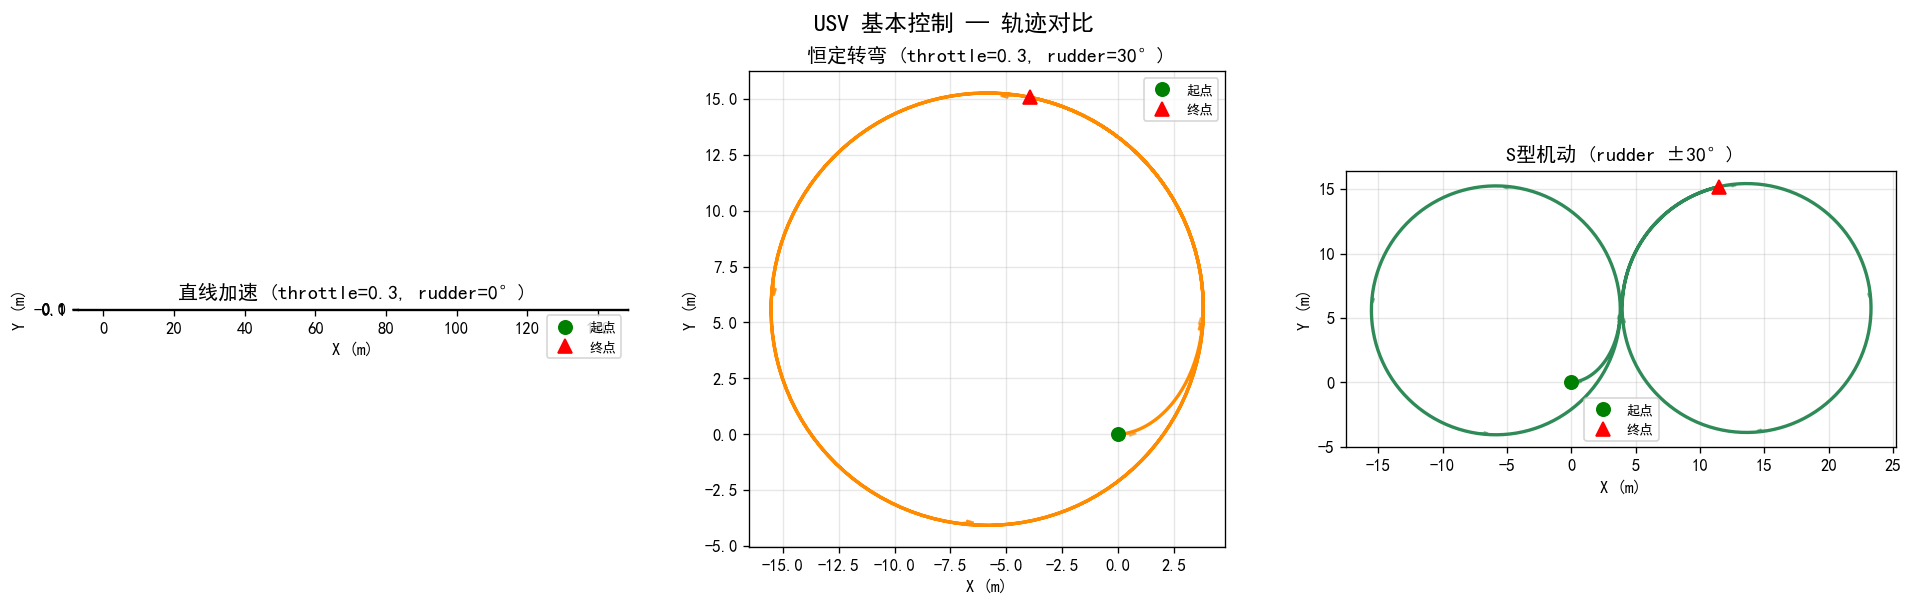

In [13]:
# ==================== 绘制轨迹对比 ====================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, log, title, color in [
    (axes[0], log1, '直线加速 (throttle=0.3, rudder=0°)', 'steelblue'),
    (axes[1], log2, '恒定转弯 (throttle=0.3, rudder=30°)', 'darkorange'),
    (axes[2], log3, 'S型机动 (rudder ±30°)', 'seagreen')
]:
    ax.plot(log['x'], log['y'], '-', color=color, linewidth=2)
    ax.plot(log['x'][0], log['y'][0], 'go', markersize=8, label='起点')
    ax.plot(log['x'][-1], log['y'][-1], 'r^', markersize=8, label='终点')
    
    # 每隔一定步数绘制航向箭头
    step_interval = 30
    for i in range(0, len(log['x']), step_interval):
        dx = np.cos(np.radians(log['heading'][i])) * 0.5
        dy = np.sin(np.radians(log['heading'][i])) * 0.5
        ax.arrow(log['x'][i], log['y'][i], dx, dy,
                head_width=0.2, fc=color, ec=color, alpha=0.6)
    
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle('USV 基本控制 — 轨迹对比', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

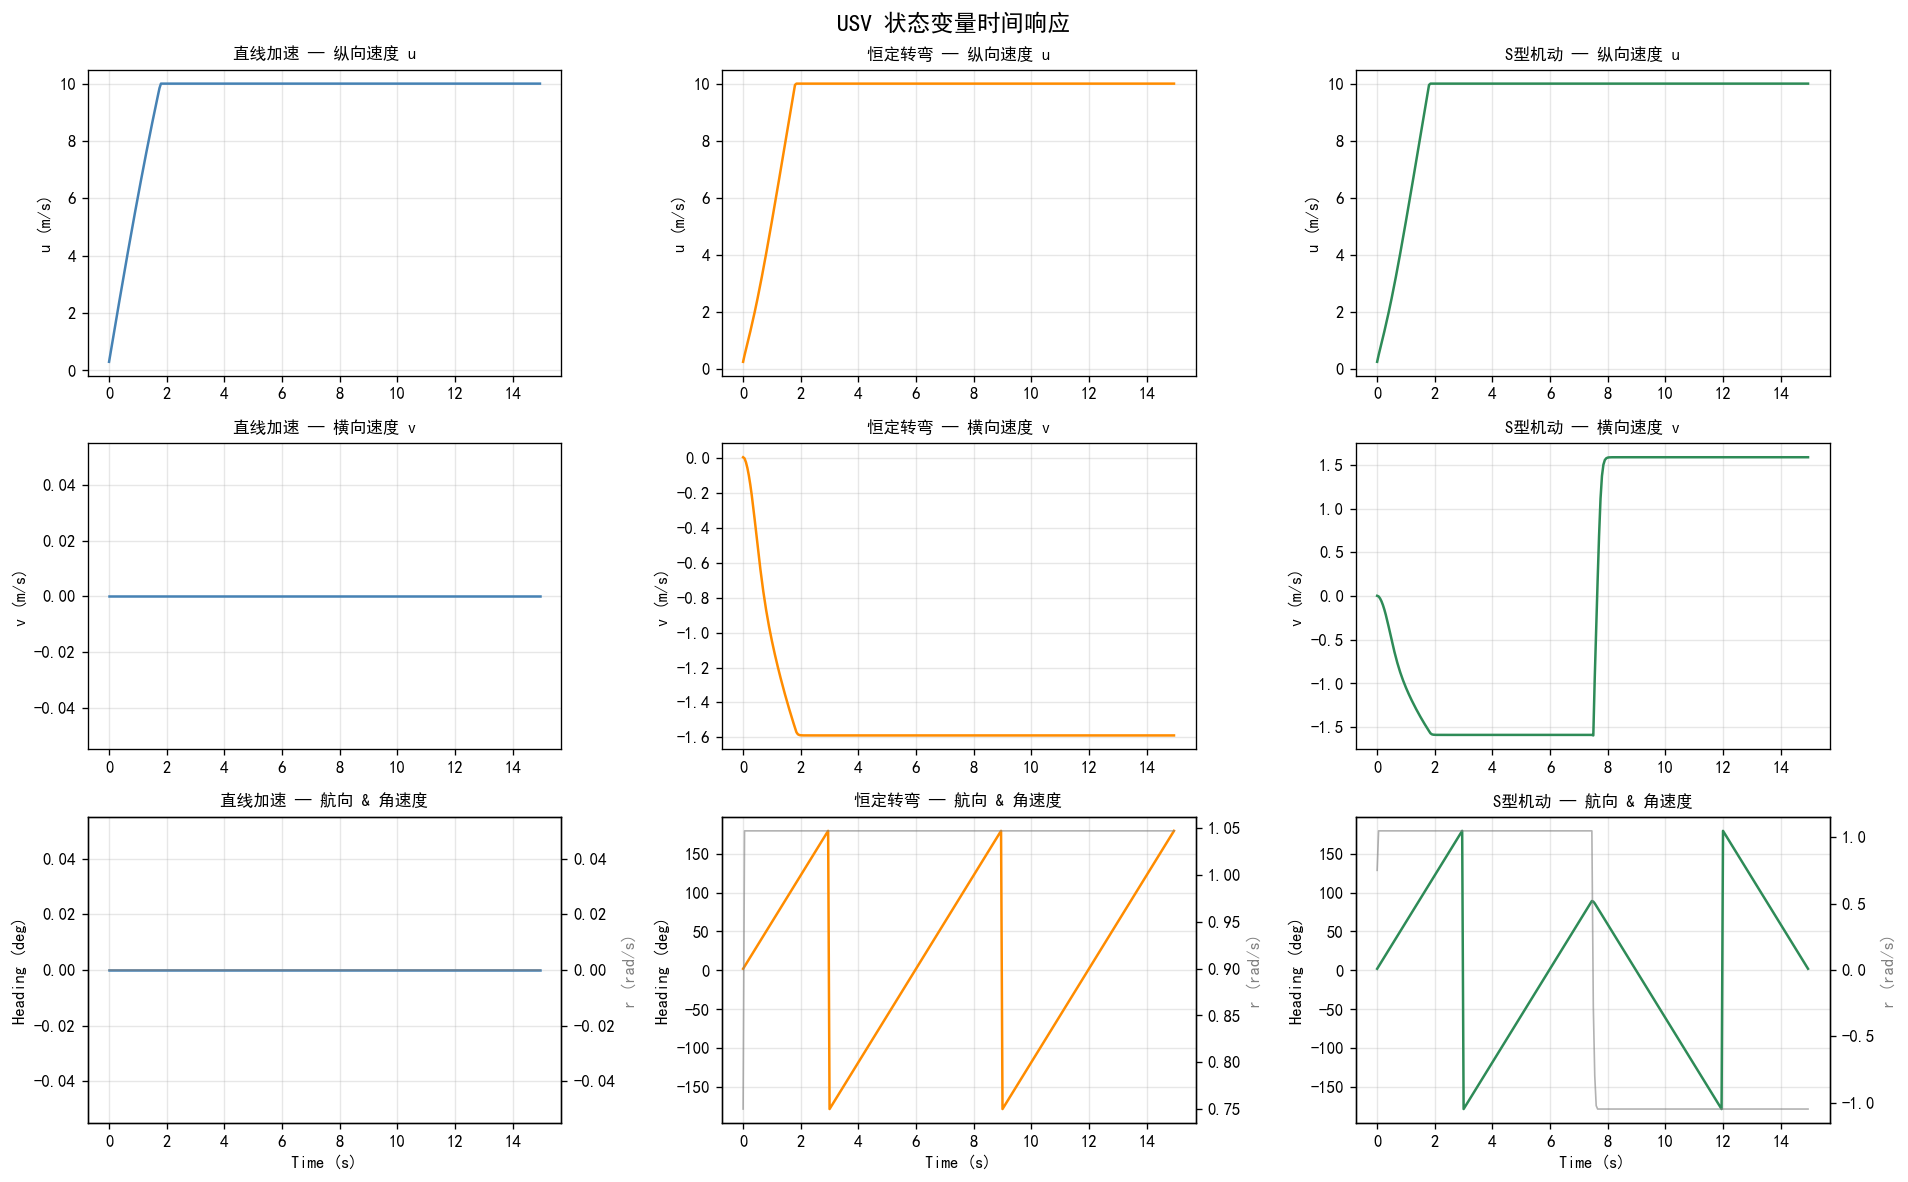

In [14]:
# ==================== 绘制状态变量时间响应 ====================
fig, axes = plt.subplots(3, 3, figsize=(16, 10))

labels = ['直线加速', '恒定转弯', 'S型机动']
colors = ['steelblue', 'darkorange', 'seagreen']
logs = [log1, log2, log3]

# 第一行: 纵向速度 u
for i, (log, label, c) in enumerate(zip(logs, labels, colors)):
    axes[0, i].plot(log['time'], log['u'], color=c, linewidth=1.5)
    axes[0, i].set_title(f'{label} — 纵向速度 u', fontsize=10)
    axes[0, i].set_ylabel('u (m/s)')
    axes[0, i].grid(True, alpha=0.3)

# 第二行: 横向速度 v & 角速度 r
for i, (log, label, c) in enumerate(zip(logs, labels, colors)):
    ax2 = axes[1, i]
    ax2.plot(log['time'], log['v'], color=c, linewidth=1.5, label='v (横向)')
    ax2.set_title(f'{label} — 横向速度 v', fontsize=10)
    ax2.set_ylabel('v (m/s)')
    ax2.grid(True, alpha=0.3)

# 第三行: 航向角 & 角速度
for i, (log, label, c) in enumerate(zip(logs, labels, colors)):
    ax3 = axes[2, i]
    ax3.plot(log['time'], log['heading'], color=c, linewidth=1.5, label='heading')
    ax3_twin = ax3.twinx()
    ax3_twin.plot(log['time'], log['r'], color='gray', linewidth=1, alpha=0.6, label='r (角速度)')
    ax3.set_title(f'{label} — 航向 & 角速度', fontsize=10)
    ax3.set_ylabel('Heading (deg)')
    ax3_twin.set_ylabel('r (rad/s)', color='gray')
    ax3.set_xlabel('Time (s)')
    ax3.grid(True, alpha=0.3)

plt.suptitle('USV 状态变量时间响应', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. 不同油门强度下的速度响应

测试不同油门值 (0.1, 0.3, 0.5, 0.8, 1.0) 下 USV 的加速特性和稳态速度

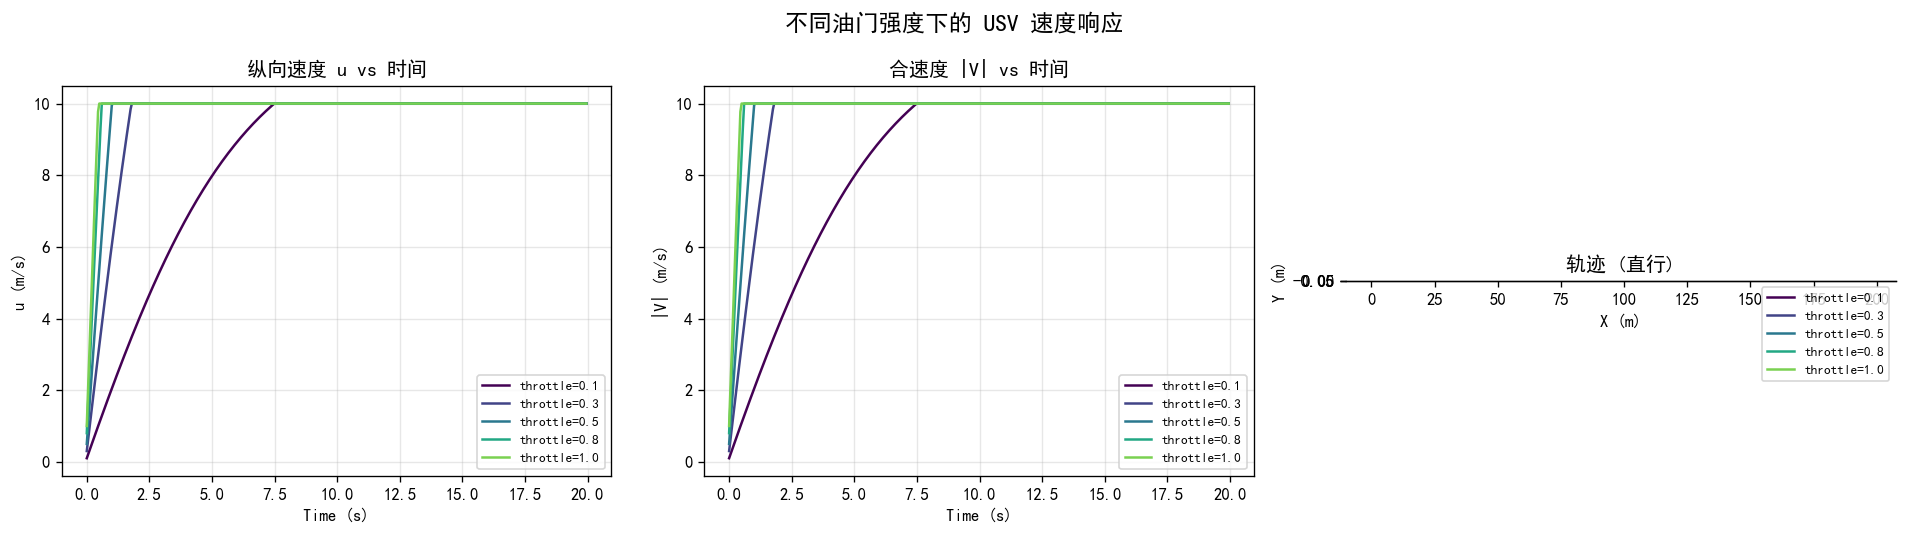

In [15]:
# ==================== 不同油门的速度响应 ====================
throttle_values = [0.1, 0.3, 0.5, 0.8, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

cmap = plt.cm.viridis
colors_t = [cmap(i / len(throttle_values)) for i in range(len(throttle_values))]

for thr, c in zip(throttle_values, colors_t):
    _, log = simulate_usv(0, 0, 0.0,
                          throttle_fn=lambda t, thr=thr: thr,
                          rudder_fn=lambda t: 0.0,
                          steps=400)
    
    speed = np.sqrt(log['u']**2 + log['v']**2)
    axes[0].plot(log['time'], log['u'], color=c, linewidth=1.5, label=f'throttle={thr}')
    axes[1].plot(log['time'], speed, color=c, linewidth=1.5, label=f'throttle={thr}')
    axes[2].plot(log['x'], log['y'], color=c, linewidth=1.5, label=f'throttle={thr}')

axes[0].set_title('纵向速度 u vs 时间')
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('u (m/s)')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].set_title('合速度 |V| vs 时间')
axes[1].set_xlabel('Time (s)'); axes[1].set_ylabel('|V| (m/s)')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

axes[2].set_title('轨迹 (直行)')
axes[2].set_xlabel('X (m)'); axes[2].set_ylabel('Y (m)')
axes[2].set_aspect('equal')
axes[2].legend(fontsize=8); axes[2].grid(True, alpha=0.3)

plt.suptitle('不同油门强度下的 USV 速度响应', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. 洋流场可视化

展示环境中的解析洋流场（基于 Double-Gyre 模型），以及洋流随时间的变化

C:\Windows\Temp\ipykernel_34956\867597921.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


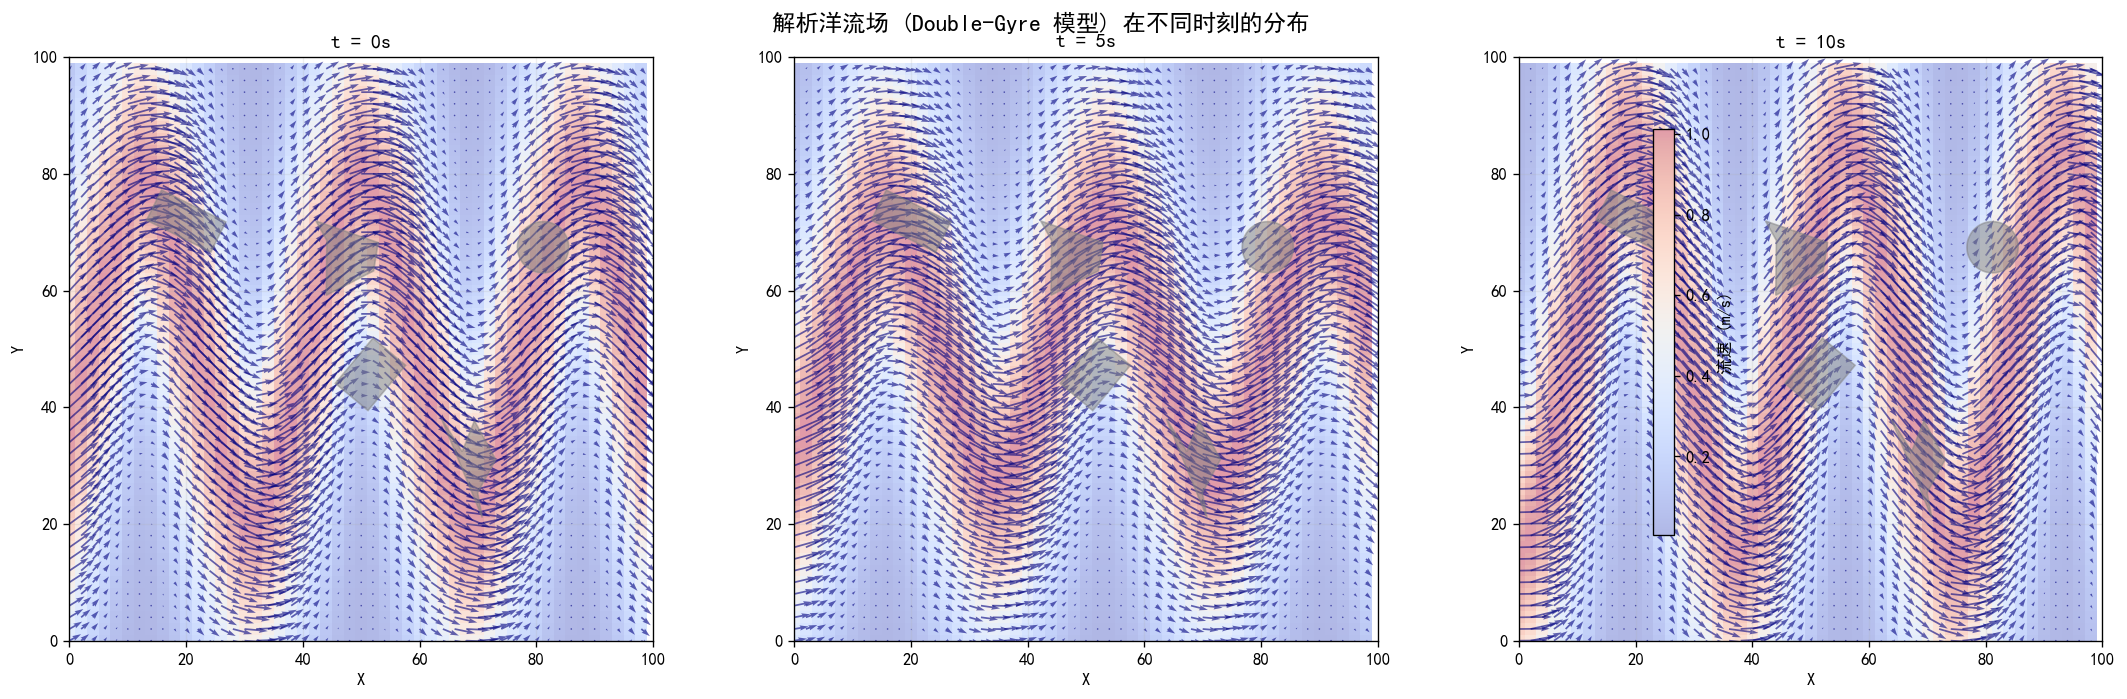

In [16]:
# ==================== 洋流场可视化 ====================
# 创建一个简单环境用于获取洋流数据
env = MyUsvEnv(
    num_targets=3, num_obstacles=5,
    seed=42, current_type="generated",
    use_random_shapes=True
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

time_steps = [0, 5, 10]
X, Y = np.meshgrid(np.arange(0, 100, 2), np.arange(0, 100, 2))

for ax, t_val in zip(axes, time_steps):
    UU = np.zeros_like(X, dtype=float)
    VV = np.zeros_like(Y, dtype=float)
    
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            u, v = env._calculate_analytic_current(X[i, j], Y[i, j], t_val)
            UU[i, j] = u
            VV[i, j] = v
    
    speed = np.sqrt(UU**2 + VV**2)
    
    # 速度场着色
    c = ax.pcolormesh(X, Y, speed, cmap='coolwarm', alpha=0.4, shading='auto')
    # 矢量场
    ax.quiver(X, Y, UU, VV, scale=15, width=0.003, color='navy', alpha=0.6)
    
    # 绘制障碍物
    for obs in env.obstacles:
        if hasattr(obs, 'geometry'):
            xs, ys = obs.geometry.exterior.xy
            ax.fill(xs, ys, color='gray', alpha=0.5)
    
    ax.set_title(f't = {t_val}s', fontsize=12, fontweight='bold')
    ax.set_xlabel('X'); ax.set_ylabel('Y')
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2)

plt.suptitle('解析洋流场 (Double-Gyre 模型) 在不同时刻的分布', fontsize=14, fontweight='bold')
plt.colorbar(c, ax=axes, label='流速 (m/s)', shrink=0.8)
plt.tight_layout()
plt.show()

## 4. 无洋流 vs 有洋流 — USV 控制效果对比

核心实验：对比相同控制输入下，USV 在**无洋流**和**有洋流**环境中的轨迹差异

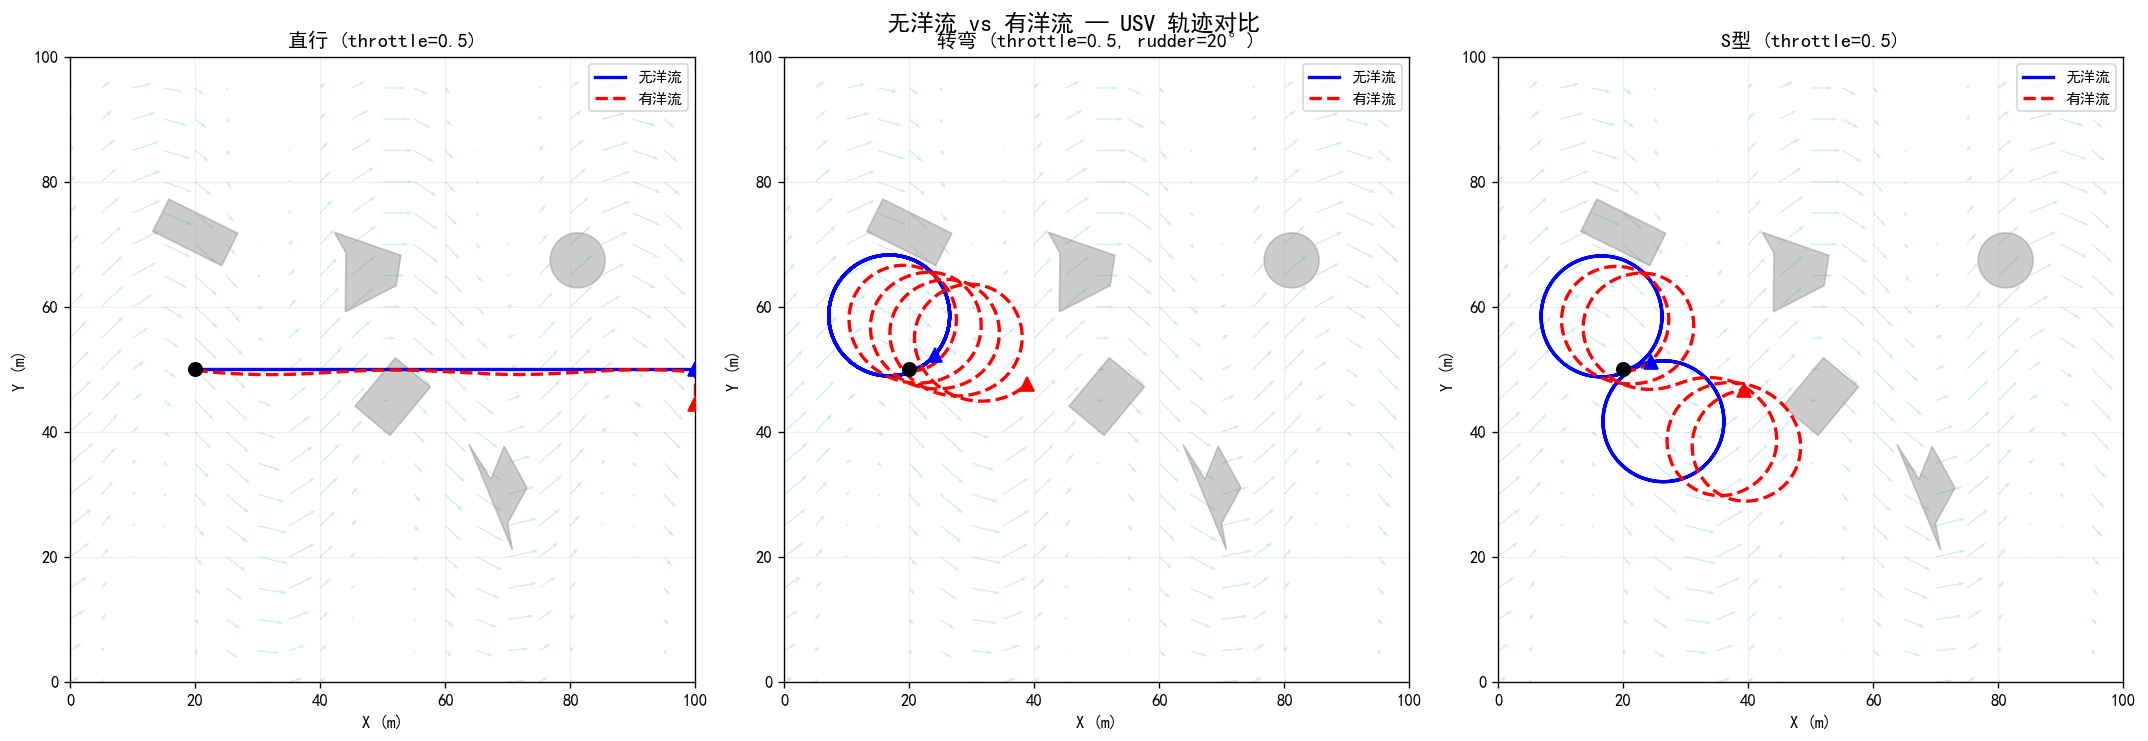

In [17]:
# ==================== 无洋流 vs 有洋流对比仿真 ====================

def simulate_usv_with_current(x0, y0, heading0, throttle_fn, rudder_fn,
                               env, steps=500, dt=0.05, apply_current=True):
    """
    在环境中仿真USV，可选择是否叠加洋流
    """
    usv = USV(x=x0, y=y0, heading=heading0, mass=50.0, inertia=5.0, dt=dt)
    
    log = {'x': [], 'y': [], 'heading': [], 'u': [], 'v': [], 'r': [],
           'flow_u': [], 'flow_v': [], 'time': []}
    
    current_time = 0.0
    for t in range(steps):
        throttle = throttle_fn(t)
        rudder = rudder_fn(t)
        
        # USV动力学更新
        usv.step(throttle, rudder)
        
        # 叠加洋流
        if apply_current:
            flow_u, flow_v = env._calculate_analytic_current(usv.x, usv.y, current_time)
            usv.x += flow_u * dt
            usv.y += flow_v * dt
        else:
            flow_u, flow_v = 0.0, 0.0
        
        # 边界限制
        usv.x = np.clip(usv.x, 0, 100)
        usv.y = np.clip(usv.y, 0, 100)
        
        current_time += dt
        
        log['x'].append(usv.x)
        log['y'].append(usv.y)
        log['heading'].append(np.degrees(usv.heading))
        log['u'].append(usv.u)
        log['v'].append(usv.v)
        log['r'].append(usv.r)
        log['flow_u'].append(flow_u)
        log['flow_v'].append(flow_v)
        log['time'].append(current_time)
    
    for k in log:
        log[k] = np.array(log[k])
    return usv, log

# ---- 三种控制场景 x 有无洋流 ----
scenarios = [
    ("直行 (throttle=0.5)", lambda t: 0.5, lambda t: 0.0),
    ("转弯 (throttle=0.5, rudder=20°)", lambda t: 0.5, lambda t: np.radians(20)),
    ("S型 (throttle=0.5)", lambda t: 0.5, 
     lambda t: np.radians(25) if t < 250 else np.radians(-25)),
]

start_x, start_y, start_heading = 20.0, 50.0, 0.0

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, thr_fn, rud_fn) in zip(axes, scenarios):
    # 无洋流
    _, log_no = simulate_usv_with_current(
        start_x, start_y, start_heading, thr_fn, rud_fn,
        env, steps=500, apply_current=False)
    
    # 有洋流
    _, log_yes = simulate_usv_with_current(
        start_x, start_y, start_heading, thr_fn, rud_fn,
        env, steps=500, apply_current=True)
    
    # 绘制洋流背景（稀疏矢量场）
    Xg, Yg = np.meshgrid(np.arange(0, 100, 5), np.arange(0, 100, 5))
    Ug = np.zeros_like(Xg, dtype=float)
    Vg = np.zeros_like(Yg, dtype=float)
    for i in range(Xg.shape[0]):
        for j in range(Xg.shape[1]):
            u, v = env._calculate_analytic_current(Xg[i,j], Yg[i,j], 0)
            Ug[i,j] = u; Vg[i,j] = v
    ax.quiver(Xg, Yg, Ug, Vg, scale=20, width=0.002, color='skyblue', alpha=0.4)
    
    # 绘制障碍物
    for obs in env.obstacles:
        xs, ys = obs.geometry.exterior.xy
        ax.fill(xs, ys, color='gray', alpha=0.4)
    
    # 轨迹
    ax.plot(log_no['x'], log_no['y'], 'b-', linewidth=2, label='无洋流', zorder=5)
    ax.plot(log_yes['x'], log_yes['y'], 'r--', linewidth=2, label='有洋流', zorder=5)
    
    # 起终点
    ax.plot(start_x, start_y, 'ko', markersize=8, zorder=6)
    ax.plot(log_no['x'][-1], log_no['y'][-1], 'b^', markersize=8, zorder=6)
    ax.plot(log_yes['x'][-1], log_yes['y'][-1], 'r^', markersize=8, zorder=6)
    
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_aspect('equal')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2)

plt.suptitle('无洋流 vs 有洋流 — USV 轨迹对比', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

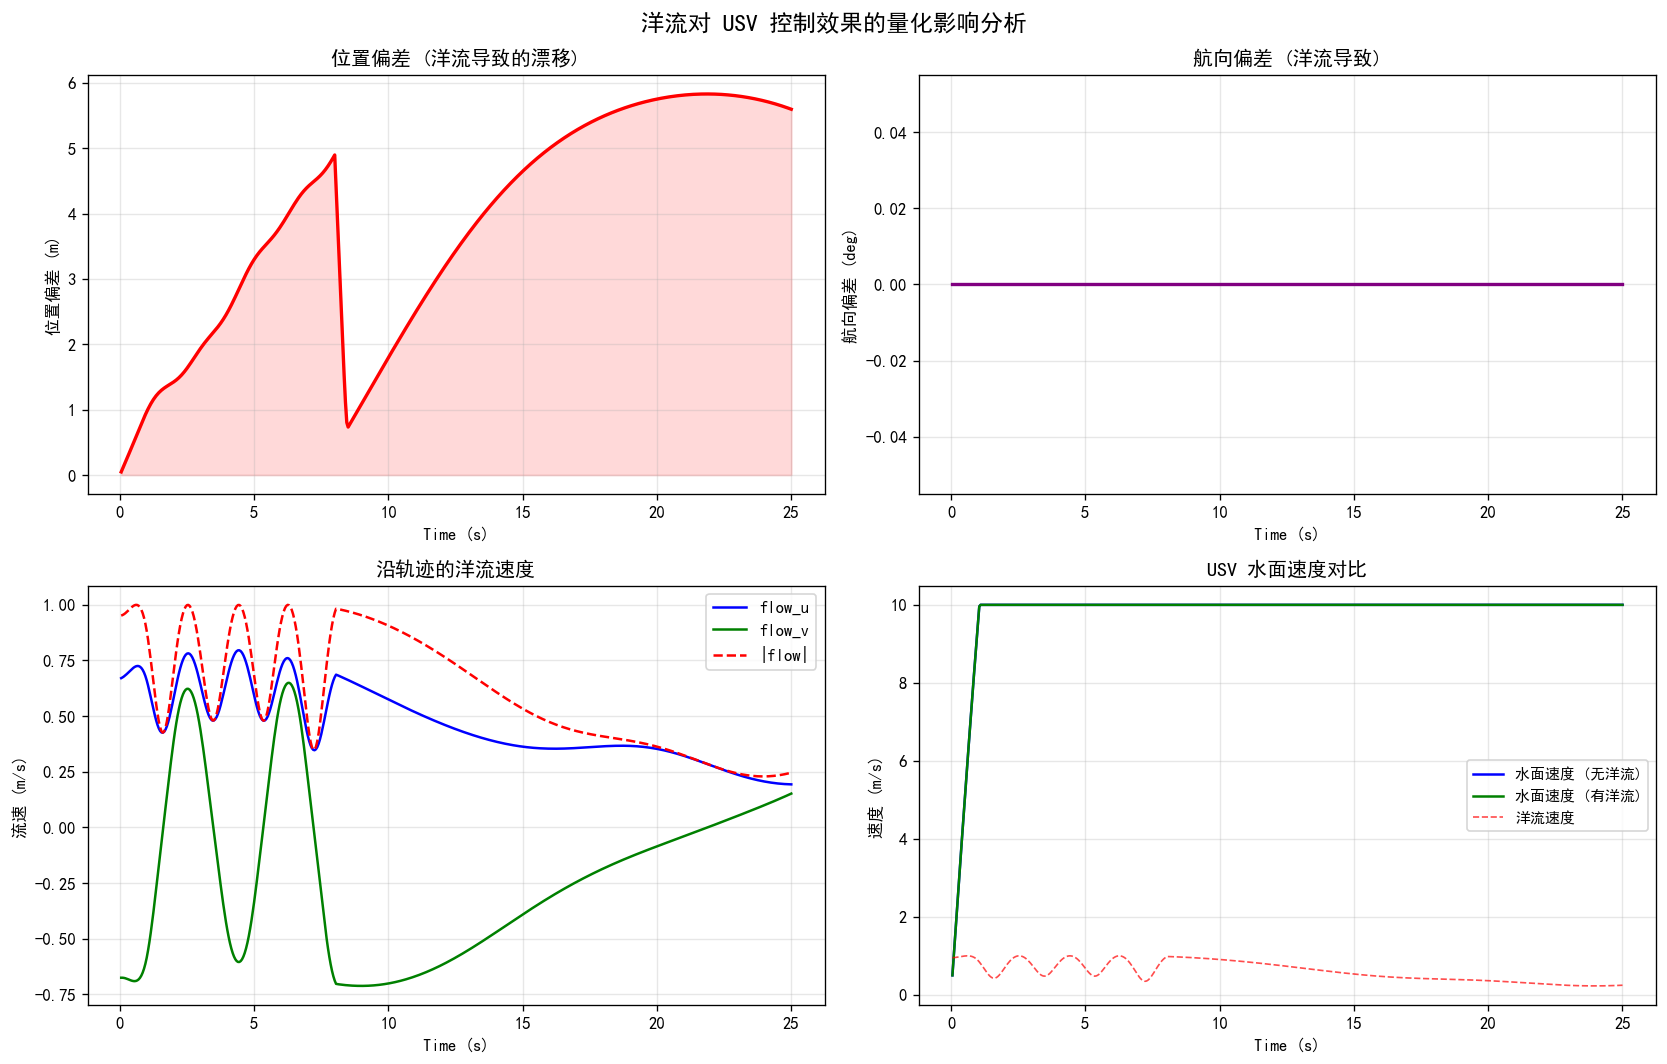

洋流影响统计 (直行 500 步, throttle=0.5)
  最大位置偏差: 5.83 m
  终点位置偏差: 5.60 m
  平均洋流速度: 0.603 m/s
  最大洋流速度: 1.000 m/s
  终点 (无洋流): (100.0, 50.0)
  终点 (有洋流): (100.0, 44.4)


In [18]:
# ==================== 洋流影响的量化分析 ====================
# 对比直行场景下，有无洋流对速度和位置的影响

_, log_no_curr = simulate_usv_with_current(
    20, 50, 0.0, lambda t: 0.5, lambda t: 0.0,
    env, steps=500, apply_current=False)

_, log_with_curr = simulate_usv_with_current(
    20, 50, 0.0, lambda t: 0.5, lambda t: 0.0,
    env, steps=500, apply_current=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 位置偏差
dx = log_with_curr['x'] - log_no_curr['x']
dy = log_with_curr['y'] - log_no_curr['y']
pos_error = np.sqrt(dx**2 + dy**2)

axes[0, 0].plot(log_no_curr['time'], pos_error, 'r-', linewidth=2)
axes[0, 0].set_title('位置偏差 (洋流导致的漂移)', fontweight='bold')
axes[0, 0].set_xlabel('Time (s)'); axes[0, 0].set_ylabel('位置偏差 (m)')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].fill_between(log_no_curr['time'], 0, pos_error, alpha=0.15, color='red')

# 航向偏差
heading_diff = log_with_curr['heading'] - log_no_curr['heading']
axes[0, 1].plot(log_no_curr['time'], heading_diff, 'purple', linewidth=2)
axes[0, 1].set_title('航向偏差 (洋流导致)', fontweight='bold')
axes[0, 1].set_xlabel('Time (s)'); axes[0, 1].set_ylabel('航向偏差 (deg)')
axes[0, 1].grid(True, alpha=0.3)

# 洋流速度沿轨迹的变化
flow_speed = np.sqrt(log_with_curr['flow_u']**2 + log_with_curr['flow_v']**2)
axes[1, 0].plot(log_with_curr['time'], log_with_curr['flow_u'], 'b-', label='flow_u', linewidth=1.5)
axes[1, 0].plot(log_with_curr['time'], log_with_curr['flow_v'], 'g-', label='flow_v', linewidth=1.5)
axes[1, 0].plot(log_with_curr['time'], flow_speed, 'r--', label='|flow|', linewidth=1.5)
axes[1, 0].set_title('沿轨迹的洋流速度', fontweight='bold')
axes[1, 0].set_xlabel('Time (s)'); axes[1, 0].set_ylabel('流速 (m/s)')
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

# USV实际地速 vs 水面速度
usv_speed_no = np.sqrt(log_no_curr['u']**2 + log_no_curr['v']**2)
usv_speed_yes = np.sqrt(log_with_curr['u']**2 + log_with_curr['v']**2)

# 实际地速 = USV水面速度 + 洋流
ground_speed_x = log_with_curr['u'] * np.cos(np.radians(log_with_curr['heading'])) + log_with_curr['flow_u']
ground_speed_y = log_with_curr['u'] * np.sin(np.radians(log_with_curr['heading'])) + log_with_curr['flow_v']
ground_speed = np.sqrt(ground_speed_x**2 + ground_speed_y**2)

axes[1, 1].plot(log_no_curr['time'], usv_speed_no, 'b-', label='水面速度 (无洋流)', linewidth=1.5)
axes[1, 1].plot(log_with_curr['time'], usv_speed_yes, 'g-', label='水面速度 (有洋流)', linewidth=1.5)
axes[1, 1].plot(log_with_curr['time'], flow_speed, 'r--', label='洋流速度', linewidth=1, alpha=0.7)
axes[1, 1].set_title('USV 水面速度对比', fontweight='bold')
axes[1, 1].set_xlabel('Time (s)'); axes[1, 1].set_ylabel('速度 (m/s)')
axes[1, 1].legend(fontsize=9); axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('洋流对 USV 控制效果的量化影响分析', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 打印统计
print("=" * 60)
print("洋流影响统计 (直行 500 步, throttle=0.5)")
print("=" * 60)
print(f"  最大位置偏差: {pos_error.max():.2f} m")
print(f"  终点位置偏差: {pos_error[-1]:.2f} m")
print(f"  平均洋流速度: {flow_speed.mean():.3f} m/s")
print(f"  最大洋流速度: {flow_speed.max():.3f} m/s")
print(f"  终点 (无洋流): ({log_no_curr['x'][-1]:.1f}, {log_no_curr['y'][-1]:.1f})")
print(f"  终点 (有洋流): ({log_with_curr['x'][-1]:.1f}, {log_with_curr['y'][-1]:.1f})")

## 5. 不同起始位置下洋流对 USV 的影响

从环境中不同区域出发，观察洋流对轨迹的影响程度（洋流在不同区域强度不同）

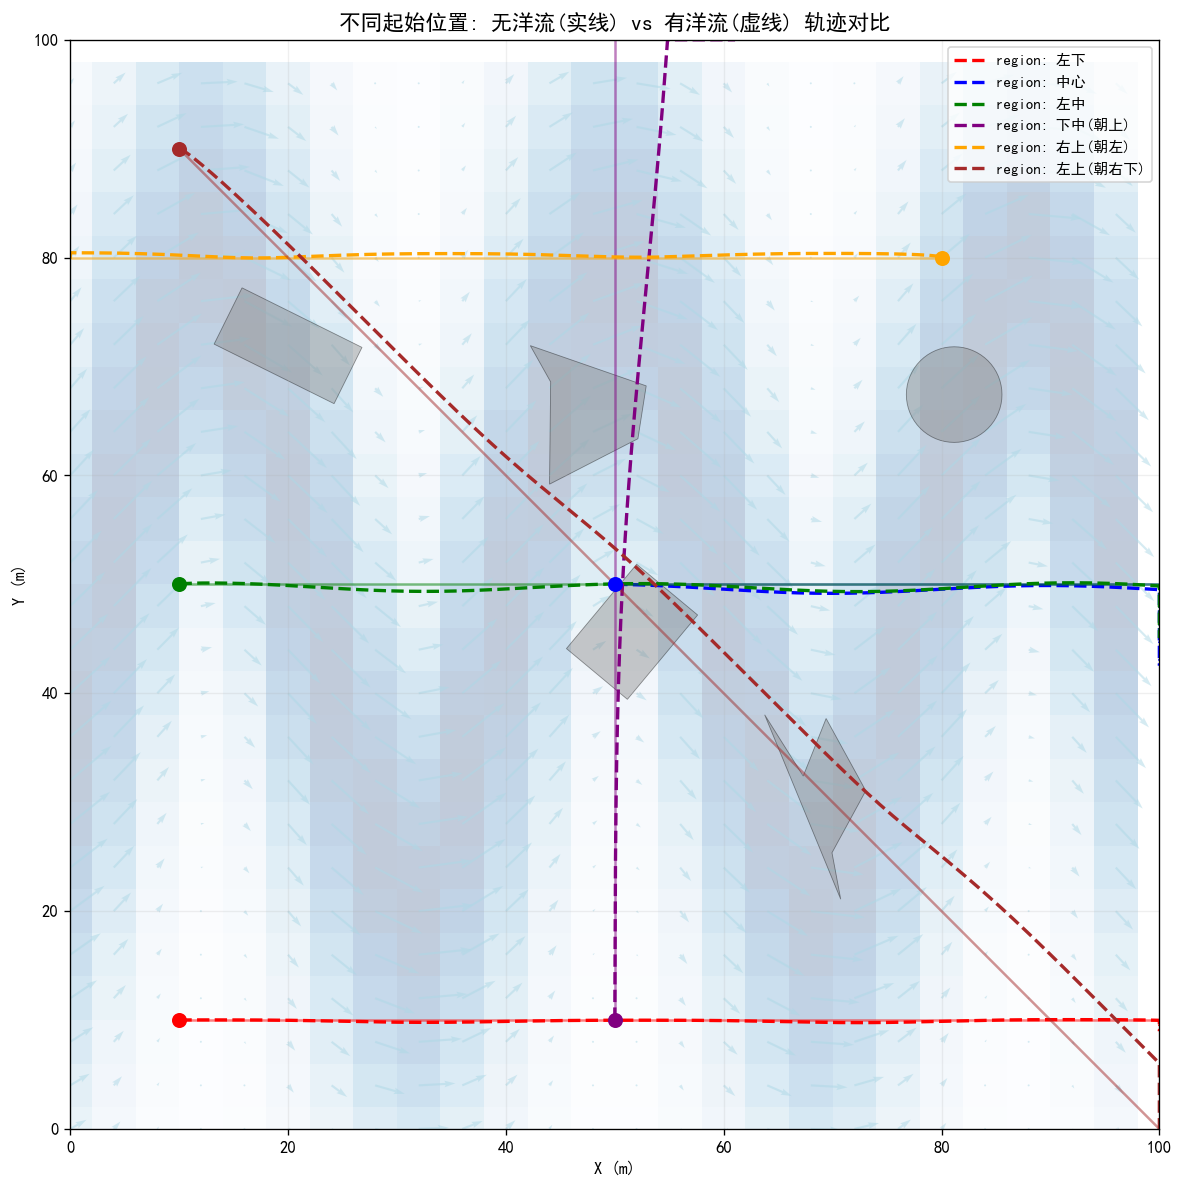

In [19]:
# ==================== 不同起始位置的洋流影响 ====================
start_positions = [
    (10, 10, 0.0,   'region: 左下'),
    (50, 50, 0.0,   'region: 中心'),
    (10, 50, 0.0,   'region: 左中'),
    (50, 10, np.pi/2, 'region: 下中(朝上)'),
    (80, 80, np.pi,   'region: 右上(朝左)'),
    (10, 90, -np.pi/4,'region: 左上(朝右下)'),
]

fig, ax = plt.subplots(figsize=(10, 10))

# 绘制洋流场背景
Xg, Yg = np.meshgrid(np.arange(0, 100, 4), np.arange(0, 100, 4))
Ug = np.zeros_like(Xg, dtype=float)
Vg = np.zeros_like(Yg, dtype=float)
for i in range(Xg.shape[0]):
    for j in range(Xg.shape[1]):
        u, v = env._calculate_analytic_current(Xg[i,j], Yg[i,j], 0)
        Ug[i,j] = u; Vg[i,j] = v
speed_bg = np.sqrt(Ug**2 + Vg**2)
ax.pcolormesh(Xg, Yg, speed_bg, cmap='Blues', alpha=0.25, shading='auto')
ax.quiver(Xg, Yg, Ug, Vg, scale=20, width=0.002, color='lightblue', alpha=0.5)

# 绘制障碍物
for obs in env.obstacles:
    xs, ys = obs.geometry.exterior.xy
    ax.fill(xs, ys, color='gray', alpha=0.4, edgecolor='black', linewidth=0.5)

colors_sp = ['red', 'blue', 'green', 'purple', 'orange', 'brown']

for (sx, sy, sh, label), c in zip(start_positions, colors_sp):
    # 无洋流
    _, log_n = simulate_usv_with_current(
        sx, sy, sh, lambda t: 0.5, lambda t: 0.0,
        env, steps=400, apply_current=False)
    # 有洋流
    _, log_c = simulate_usv_with_current(
        sx, sy, sh, lambda t: 0.5, lambda t: 0.0,
        env, steps=400, apply_current=True)
    
    ax.plot(log_n['x'], log_n['y'], '-', color=c, linewidth=1.5, alpha=0.5)
    ax.plot(log_c['x'], log_c['y'], '--', color=c, linewidth=2.0, label=label)
    ax.plot(sx, sy, 'o', color=c, markersize=8, zorder=6)
    
    # 终点偏差连线
    ax.plot([log_n['x'][-1], log_c['x'][-1]], 
            [log_n['y'][-1], log_c['y'][-1]], 
            ':', color=c, linewidth=1)

ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_aspect('equal')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
ax.set_title('不同起始位置: 无洋流(实线) vs 有洋流(虚线) 轨迹对比', fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

## 6. MyUsvEnv 环境中的完整仿真

使用 `MyUsvEnv` 环境的 `step()` 函数运行完整仿真，验证 USV 在环境中的实际控制效果（含障碍物探测、洋流叠加）

In [22]:
# ==================== MyUsvEnv 完整仿真 ====================
# 创建环境
env_test = MyUsvEnv(
    num_targets=3, num_obstacles=5,
    seed=24, record_flag=False,
    use_random_shapes=True,
    current_type="generated"
)

obs = env_test.reset(seed=24)
goal = np.array([env_test.targets[0].x, env_test.targets[0].y])

# 记录状态
log_env = {'x': [], 'y': [], 'heading': [], 'u': [], 'v': [], 'r': [],
           'throttle': [], 'rudder': [], 'sensor_min': [], 'flow_u': [], 'flow_v': []}

log_env['x'].append(env_test.usv.x)
log_env['y'].append(env_test.usv.y)

max_steps = 800
done = False

for step_i in range(max_steps):
    # 简单的目标追踪控制器
    dx = goal[0] - env_test.usv.x
    dy = goal[1] - env_test.usv.y
    desired_heading = np.arctan2(dy, dx)
    heading_error = desired_heading - env_test.usv.heading
    # 归一化到 [-pi, pi]
    heading_error = (heading_error + np.pi) % (2 * np.pi) - np.pi
    
    # P控制器
    throttle = np.clip(0.6 - 0.3 * abs(heading_error), 0.1, 0.8)
    rudder = np.clip(heading_error * 2.0, -1.0, 1.0)
    
    action = np.array([throttle, rudder], dtype=np.float32)
    obs, d, crush, truncated, info = env_test.step(action, goal)
    
    log_env['x'].append(env_test.usv.x)
    log_env['y'].append(env_test.usv.y)
    log_env['heading'].append(np.degrees(env_test.usv.heading))
    log_env['u'].append(env_test.usv.u)
    log_env['v'].append(env_test.usv.v)
    log_env['r'].append(env_test.usv.r)
    log_env['throttle'].append(throttle)
    log_env['rudder'].append(rudder)
    log_env['sensor_min'].append(min(env_test.usv.sensor_readings))
    log_env['flow_u'].append(info['flow'][0])
    log_env['flow_v'].append(info['flow'][1])
    
    if d or crush:
        print(f"  Step {step_i}: done={d}, collision={crush}")
        break

for k in log_env:
    log_env[k] = np.array(log_env[k])

dist_to_goal = np.sqrt((log_env['x'][-1] - goal[0])**2 + (log_env['y'][-1] - goal[1])**2)
print(f"仿真完成: {step_i+1} 步")
print(f"  目标: ({goal[0]:.1f}, {goal[1]:.1f})")
print(f"  终点: ({log_env['x'][-1]:.1f}, {log_env['y'][-1]:.1f})")
print(f"  距离目标: {dist_to_goal:.2f} m")

  Step 103: done=True, collision=False
仿真完成: 104 步
  目标: (59.5, 77.1)
  终点: (60.8, 74.7)
  距离目标: 2.79 m


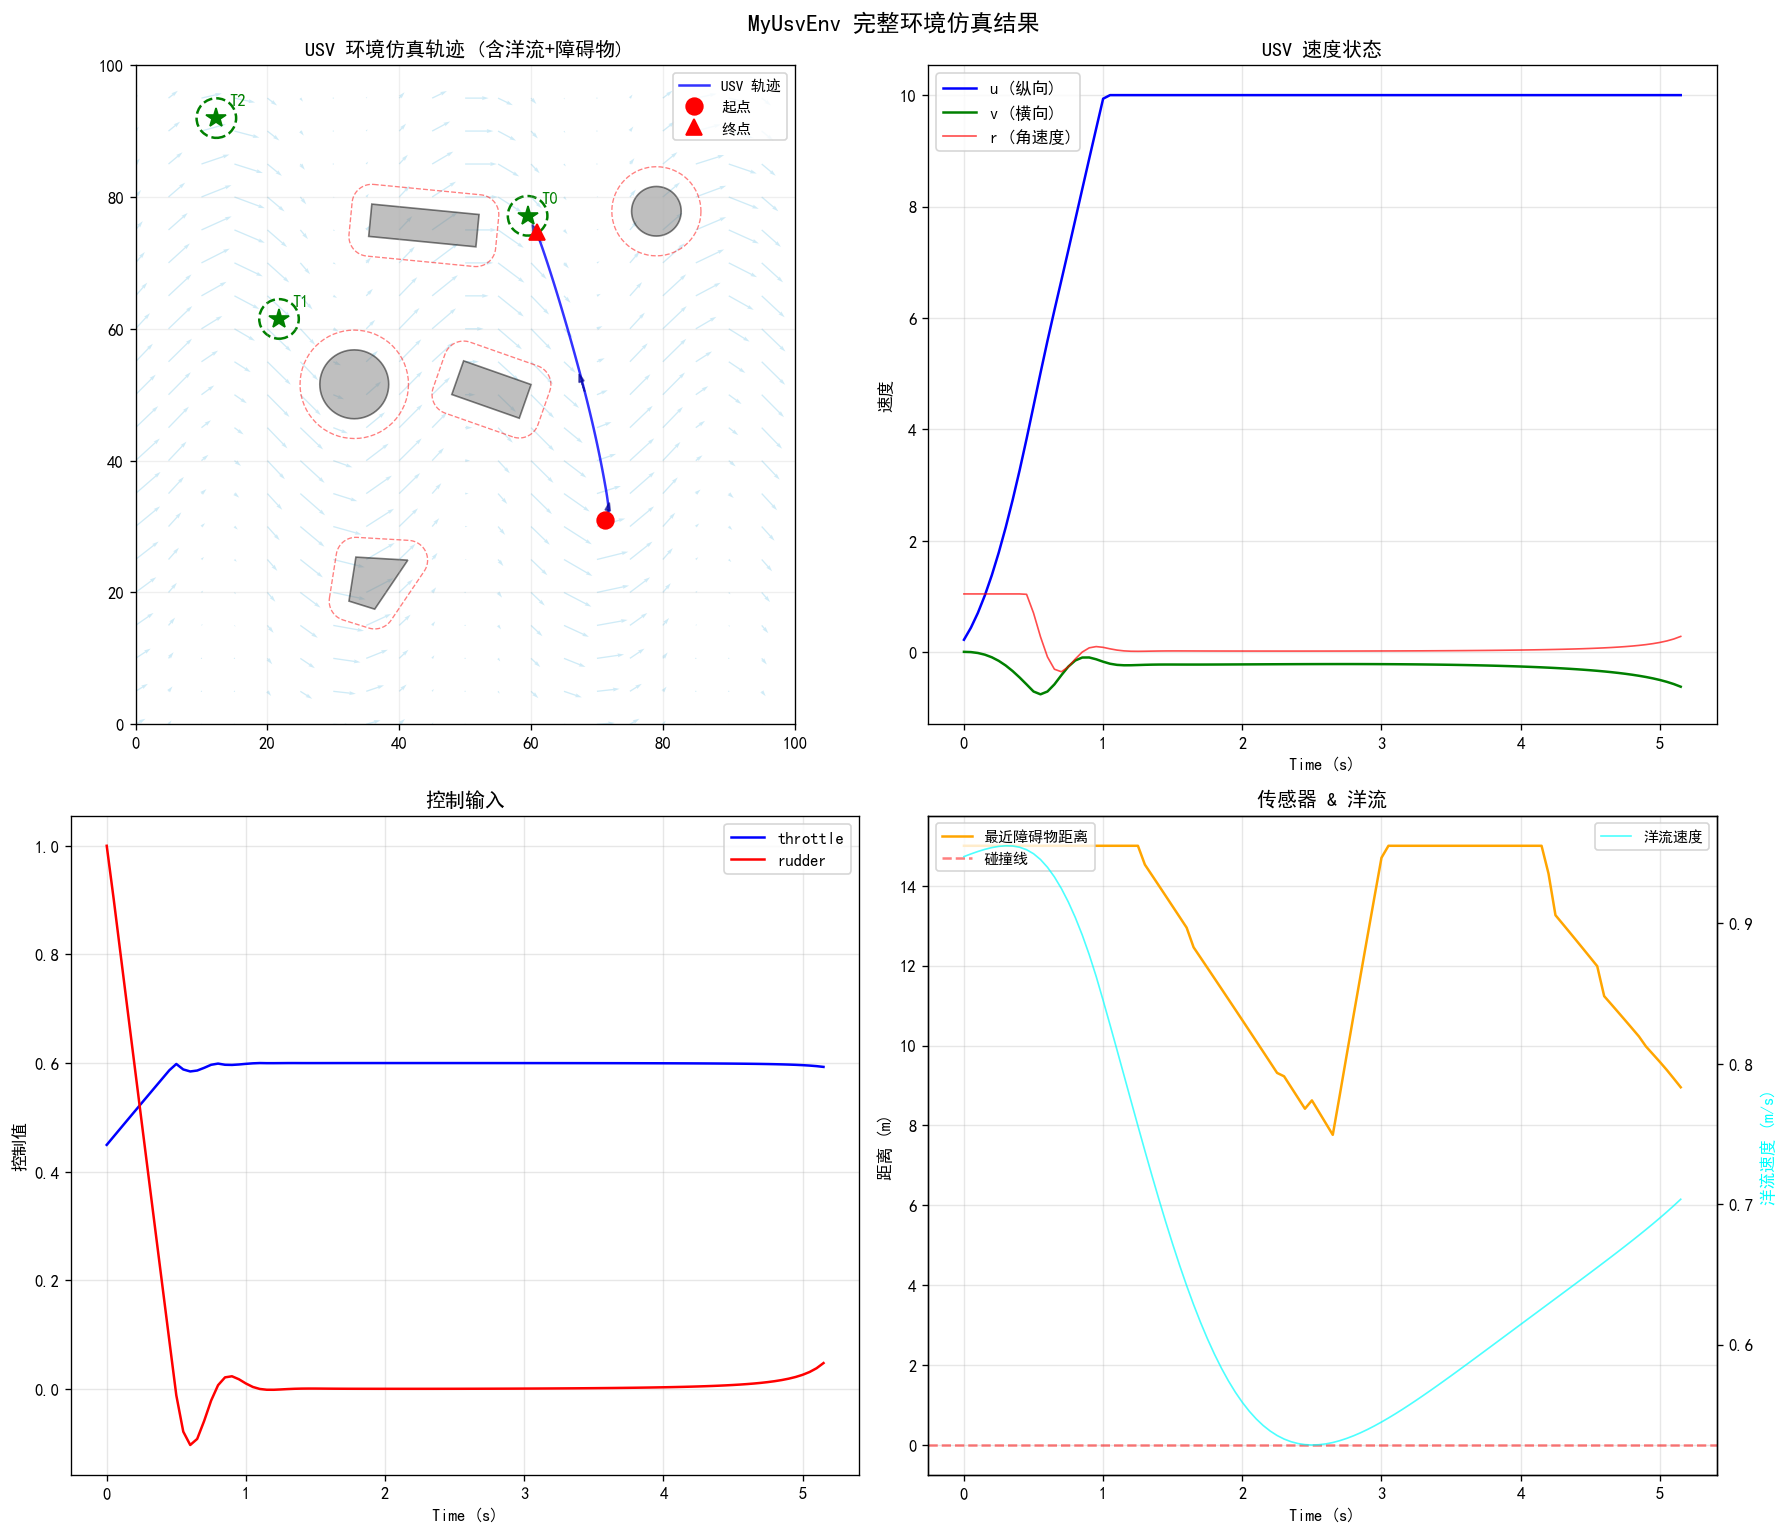

In [23]:
# ==================== 环境仿真结果可视化 ====================
fig, axes = plt.subplots(2, 2, figsize=(15, 13))

# ---- 左上: 轨迹图 ----
ax = axes[0, 0]
# 洋流背景
Xg, Yg = np.meshgrid(np.arange(0, 100, 5), np.arange(0, 100, 5))
Ug = np.zeros_like(Xg, dtype=float)
Vg = np.zeros_like(Yg, dtype=float)
for i in range(Xg.shape[0]):
    for j in range(Xg.shape[1]):
        u, v = env_test._calculate_analytic_current(Xg[i,j], Yg[i,j], 0)
        Ug[i,j] = u; Vg[i,j] = v
ax.quiver(Xg, Yg, Ug, Vg, scale=20, width=0.002, color='skyblue', alpha=0.4)

# 障碍物
for obs in env_test.obstacles:
    xs, ys = obs.geometry.exterior.xy
    ax.fill(xs, ys, color='gray', alpha=0.5, edgecolor='black')
    # 安全区
    xs_s, ys_s = obs.safety_zone.exterior.xy
    ax.plot(xs_s, ys_s, 'r--', linewidth=0.8, alpha=0.5)

# 目标
for i, t in enumerate(env_test.targets):
    circle = plt.Circle((t.x, t.y), t.radius_t, color='green', fill=False, linestyle='--', linewidth=1.5)
    ax.add_patch(circle)
    ax.plot(t.x, t.y, 'g*', markersize=12)
    ax.text(t.x + 2, t.y + 2, f'T{i}', color='green', fontsize=10, fontweight='bold')

# 轨迹
ax.plot(log_env['x'], log_env['y'], 'b-', linewidth=1.5, alpha=0.8, label='USV 轨迹')
ax.plot(log_env['x'][0], log_env['y'][0], 'ro', markersize=10, label='起点', zorder=6)
ax.plot(log_env['x'][-1], log_env['y'][-1], 'r^', markersize=10, label='终点', zorder=6)

# 每隔一段画航向箭头
for i in range(0, len(log_env['heading']), 50):
    hd = np.radians(log_env['heading'][i])
    dx = np.cos(hd) * 1.5
    dy = np.sin(hd) * 1.5
    ax.arrow(log_env['x'][i+1], log_env['y'][i+1], dx, dy,
            head_width=0.8, fc='darkblue', ec='darkblue', alpha=0.6, zorder=5)

ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_aspect('equal')
ax.set_title('USV 环境仿真轨迹 (含洋流+障碍物)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

# ---- 右上: 速度 & 控制输入 ----
ax2 = axes[0, 1]
time_arr = np.arange(len(log_env['u'])) * env_test.dt
ax2.plot(time_arr, log_env['u'], 'b-', label='u (纵向)', linewidth=1.5)
ax2.plot(time_arr, log_env['v'], 'g-', label='v (横向)', linewidth=1.5)
ax2.plot(time_arr, log_env['r'], 'r-', label='r (角速度)', linewidth=1, alpha=0.7)
ax2.set_title('USV 速度状态', fontweight='bold')
ax2.set_xlabel('Time (s)'); ax2.set_ylabel('速度')
ax2.legend(); ax2.grid(True, alpha=0.3)

# ---- 左下: 控制输入 ----
ax3 = axes[1, 0]
ax3.plot(time_arr, log_env['throttle'], 'b-', label='throttle', linewidth=1.5)
ax3.plot(time_arr, log_env['rudder'], 'r-', label='rudder', linewidth=1.5)
ax3.set_title('控制输入', fontweight='bold')
ax3.set_xlabel('Time (s)'); ax3.set_ylabel('控制值')
ax3.legend(); ax3.grid(True, alpha=0.3)

# ---- 右下: 传感器最小读数 & 洋流速度 ----
ax4 = axes[1, 1]
ax4.plot(time_arr, log_env['sensor_min'], 'orange', label='最近障碍物距离', linewidth=1.5)
ax4.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='碰撞线')

ax4_twin = ax4.twinx()
flow_mag = np.sqrt(np.array(log_env['flow_u'])**2 + np.array(log_env['flow_v'])**2)
ax4_twin.plot(time_arr, flow_mag, 'cyan', label='洋流速度', linewidth=1, alpha=0.7)
ax4_twin.set_ylabel('洋流速度 (m/s)', color='cyan')

ax4.set_title('传感器 & 洋流', fontweight='bold')
ax4.set_xlabel('Time (s)'); ax4.set_ylabel('距离 (m)')
ax4.legend(loc='upper left', fontsize=9)
ax4_twin.legend(loc='upper right', fontsize=9)
ax4.grid(True, alpha=0.3)

plt.suptitle('MyUsvEnv 完整环境仿真结果', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. USV 惯性对控制效果的影响

测试质量 (`mass`) 和转动惯量 (`inertia`) 对 USV 控制响应的影响：
- **质量影响**：质量越大 → 加速越慢、制动距离越长、稳态速度变化
- **转动惯量影响**：惯量越大 → 转向响应越慢、角速度建立时间越长、超调/振荡特性变化
- **综合影响**：S 型机动下不同惯性参数的轨迹差异

In [24]:
# ==================== 7.1 不同质量对纵向加速/制动的影响 ====================

def simulate_usv_inertia(x0, y0, heading0, throttle_fn, rudder_fn,
                          mass=50.0, inertia=5.0, steps=400, dt=0.05):
    """仿真函数：可自定义 mass 和 inertia"""
    usv = USV(x=x0, y=y0, heading=heading0, mass=mass, inertia=inertia, dt=dt)
    
    log = {'x': [], 'y': [], 'heading': [], 'u': [], 'v': [], 'r': [],
           'throttle': [], 'rudder': [], 'time': [],
           'ground_speed': [], 'x_dot': [], 'y_dot': []}
    
    for t in range(steps):
        throttle = throttle_fn(t)
        rudder = rudder_fn(t)
        usv.step(throttle, rudder)
        
        # 地面速度
        x_dot = usv.u * np.cos(usv.heading) - usv.v * np.sin(usv.heading)
        y_dot = usv.u * np.sin(usv.heading) + usv.v * np.cos(usv.heading)
        gs = np.sqrt(x_dot**2 + y_dot**2)
        
        log['x'].append(usv.x)
        log['y'].append(usv.y)
        log['heading'].append(np.degrees(usv.heading))
        log['u'].append(usv.u)
        log['v'].append(usv.v)
        log['r'].append(usv.r)
        log['throttle'].append(throttle)
        log['rudder'].append(np.degrees(rudder))
        log['time'].append(t * dt)
        log['ground_speed'].append(gs)
        log['x_dot'].append(x_dot)
        log['y_dot'].append(y_dot)
    
    for k in log:
        log[k] = np.array(log[k])
    return usv, log

# ---- 实验1: 不同质量 — 加速+松油门制动 ----
mass_values = [20, 50, 100, 200]
inertia_fixed = 5.0

# 控制输入: 前200步加速(throttle=0.5), 后200步松油门(throttle=0)
def throttle_accel_brake(t):
    return 0.5 if t < 200 else 0.0

mass_logs = {}
for m in mass_values:
    _, log = simulate_usv_inertia(
        0, 0, 0.0,
        throttle_fn=throttle_accel_brake,
        rudder_fn=lambda t: 0.0,
        mass=m, inertia=inertia_fixed, steps=400)
    mass_logs[m] = log

print("质量影响仿真完成 ✓")
for m in mass_values:
    log = mass_logs[m]
    peak_u = np.max(log['u'])
    peak_idx = np.argmax(log['u'])
    final_u = log['u'][-1]
    total_dist = log['x'][-1]
    # 90%稳态速度到达时间
    steady_u = log['u'][199]  # 加速阶段末尾
    t90_candidates = np.where(log['u'][:200] >= 0.9 * steady_u)[0]
    t90 = log['time'][t90_candidates[0]] if len(t90_candidates) > 0 else -1
    print(f"  mass={m:>4d}kg: 峰值u={peak_u:.2f} m/s, "
          f"加速末u={steady_u:.2f} m/s, 松油后u={final_u:.3f} m/s, "
          f"总位移={total_dist:.1f}m, 90%响应时间={t90:.2f}s")

质量影响仿真完成 ✓
  mass=  20kg: 峰值u=10.00 m/s, 加速末u=10.00 m/s, 松油后u=1.412 m/s, 总位移=135.7m, 90%响应时间=0.35s
  mass=  50kg: 峰值u=10.00 m/s, 加速末u=10.00 m/s, 松油后u=3.663 m/s, 总位移=154.9m, 90%响应时间=0.90s
  mass= 100kg: 峰值u=10.00 m/s, 加速末u=10.00 m/s, 松油后u=5.628 m/s, 总位移=164.5m, 90%响应时间=1.85s
  mass= 200kg: 峰值u=10.00 m/s, 加速末u=10.00 m/s, 松油后u=7.307 m/s, 总位移=164.9m, 90%响应时间=3.75s


C:\Windows\Temp\ipykernel_34956\3572750273.py:51: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()
d:\Anaconda\anaconda3\envs\RL\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


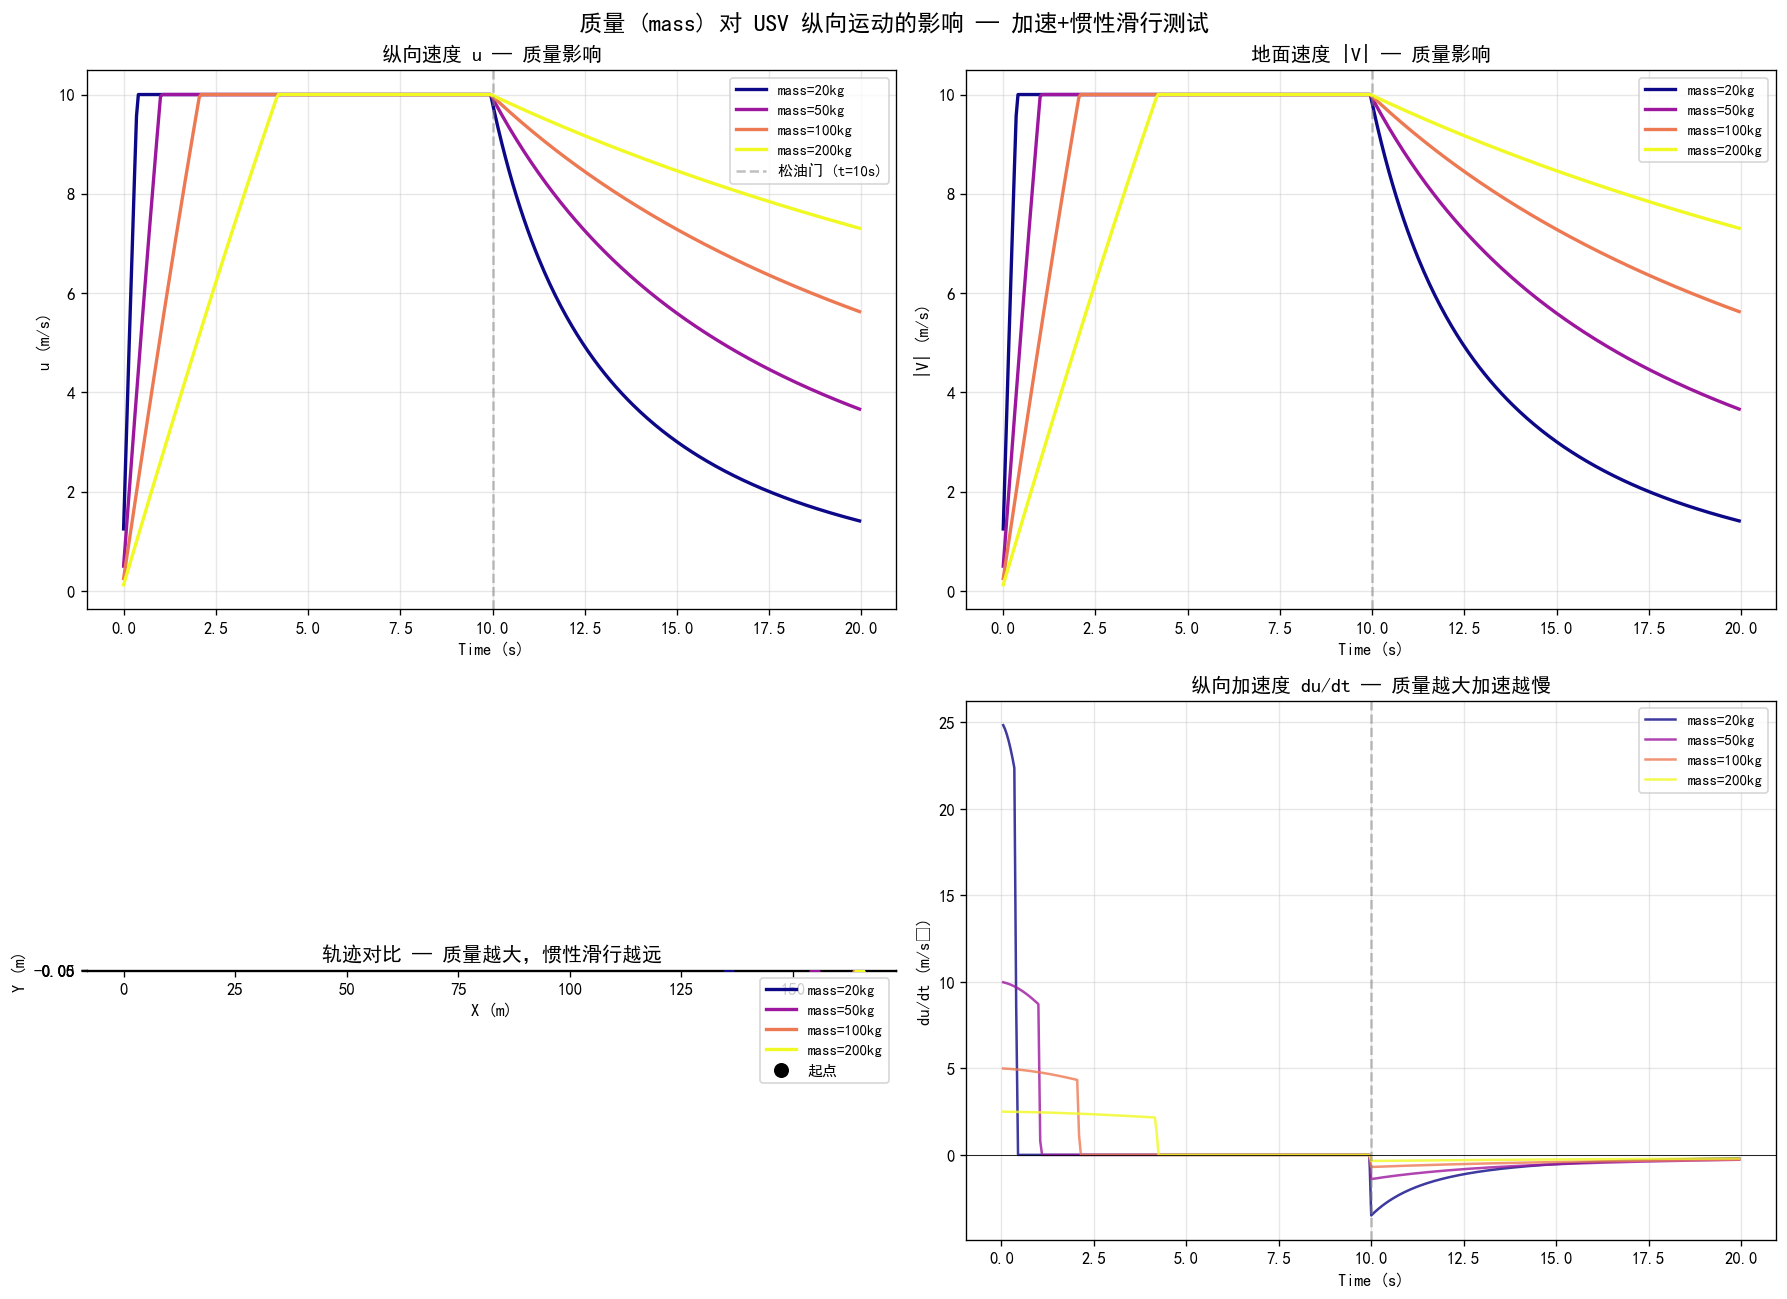

In [25]:
# ==================== 7.1 可视化: 质量对加速/制动的影响 ====================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

cmap = plt.cm.plasma
colors_m = [cmap(i / (len(mass_values) - 1)) for i in range(len(mass_values))]

# ---- 左上: 纵向速度 u vs 时间 ----
ax = axes[0, 0]
for m, c in zip(mass_values, colors_m):
    log = mass_logs[m]
    ax.plot(log['time'], log['u'], color=c, linewidth=2, label=f'mass={m}kg')
ax.axvline(x=10.0, color='gray', linestyle='--', alpha=0.5, label='松油门 (t=10s)')
ax.set_title('纵向速度 u — 质量影响', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('u (m/s)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ---- 右上: 地面速度 vs 时间 ----
ax = axes[0, 1]
for m, c in zip(mass_values, colors_m):
    log = mass_logs[m]
    ax.plot(log['time'], log['ground_speed'], color=c, linewidth=2, label=f'mass={m}kg')
ax.axvline(x=10.0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('地面速度 |V| — 质量影响', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('|V| (m/s)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ---- 左下: 轨迹 (位移) ----
ax = axes[1, 0]
for m, c in zip(mass_values, colors_m):
    log = mass_logs[m]
    ax.plot(log['x'], log['y'], color=c, linewidth=2, label=f'mass={m}kg')
    ax.plot(log['x'][-1], log['y'][-1], '^', color=c, markersize=10, zorder=5)
ax.plot(0, 0, 'ko', markersize=8, label='起点')
ax.set_title('轨迹对比 — 质量越大，惯性滑行越远', fontweight='bold')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
ax.set_aspect('equal'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ---- 右下: 加速阶段加速度对比 (du/dt 近似) ----
ax = axes[1, 1]
for m, c in zip(mass_values, colors_m):
    log = mass_logs[m]
    du_dt = np.diff(log['u']) / 0.05
    ax.plot(log['time'][1:], du_dt, color=c, linewidth=1.5, alpha=0.8, label=f'mass={m}kg')
ax.axvline(x=10.0, color='gray', linestyle='--', alpha=0.5)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_title('纵向加速度 du/dt — 质量越大加速越慢', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('du/dt (m/s²)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('质量 (mass) 对 USV 纵向运动的影响 — 加速+惯性滑行测试', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [28]:
# ==================== 7.2 不同转动惯量对转向响应的影响 ====================
inertia_values = [1, 5, 15, 30]
mass_fixed = 50.0

# 控制: 前100步直行, 100-250步左转(rudder=30°), 250-400步回正(rudder=0)
def throttle_turn_test(t):
    return 0.5

def rudder_turn_test(t):
    if t < 100:
        return 0.0
    elif t < 250:
        return np.radians(30)
    else:
        return 0.0  # 松舵 — 观察惯性带来的持续转动

inertia_logs = {}
for I in inertia_values:
    _, log = simulate_usv_inertia(
        0, 0, 0.0,
        throttle_fn=throttle_turn_test,
        rudder_fn=rudder_turn_test,
        mass=mass_fixed, inertia=I, steps=400)
    inertia_logs[I] = log

print("转动惯量影响仿真完成 ✓")
for I in inertia_values:
    log = inertia_logs[I]
    peak_r = np.max(np.abs(log['r']))
    # 松舵后角速度残余
    r_after_release = log['r'][-1]
    heading_total = log['heading'][-1] - log['heading'][0]
    # 转向开始后达到90%峰值角速度的时间
    r_segment = np.abs(log['r'][100:250])
    peak_r_seg = np.max(r_segment) if len(r_segment) > 0 else 0
    t90_r = np.where(r_segment >= 0.9 * peak_r_seg)[0]
    t90_r_time = t90_r[0] * 0.05 if len(t90_r) > 0 else -1
    print(f"  inertia={I:>3d} kg·m²: 峰值|r|={peak_r:.3f} rad/s, "
          f"松舵后r={r_after_release:.4f} rad/s, "
          f"总航向变化={heading_total:.1f}°, "
          f"角速度90%响应={t90_r_time:.2f}s")

转动惯量影响仿真完成 ✓
  inertia=  1 kg·m²: 峰值|r|=1.047 rad/s, 松舵后r=0.0133 rad/s, 总航向变化=100.3°, 角速度90%响应=0.00s
  inertia=  5 kg·m²: 峰值|r|=1.047 rad/s, 松舵后r=0.0182 rad/s, 总航向变化=103.4°, 角速度90%响应=0.00s
  inertia= 15 kg·m²: 峰值|r|=0.826 rad/s, 松舵后r=0.0193 rad/s, 总航向变化=5.6°, 角速度90%响应=0.20s
  inertia= 30 kg·m²: 峰值|r|=0.474 rad/s, 松舵后r=0.0196 rad/s, 总航向变化=-146.5°, 角速度90%响应=0.30s


C:\Windows\Temp\ipykernel_34956\2667476861.py:57: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()


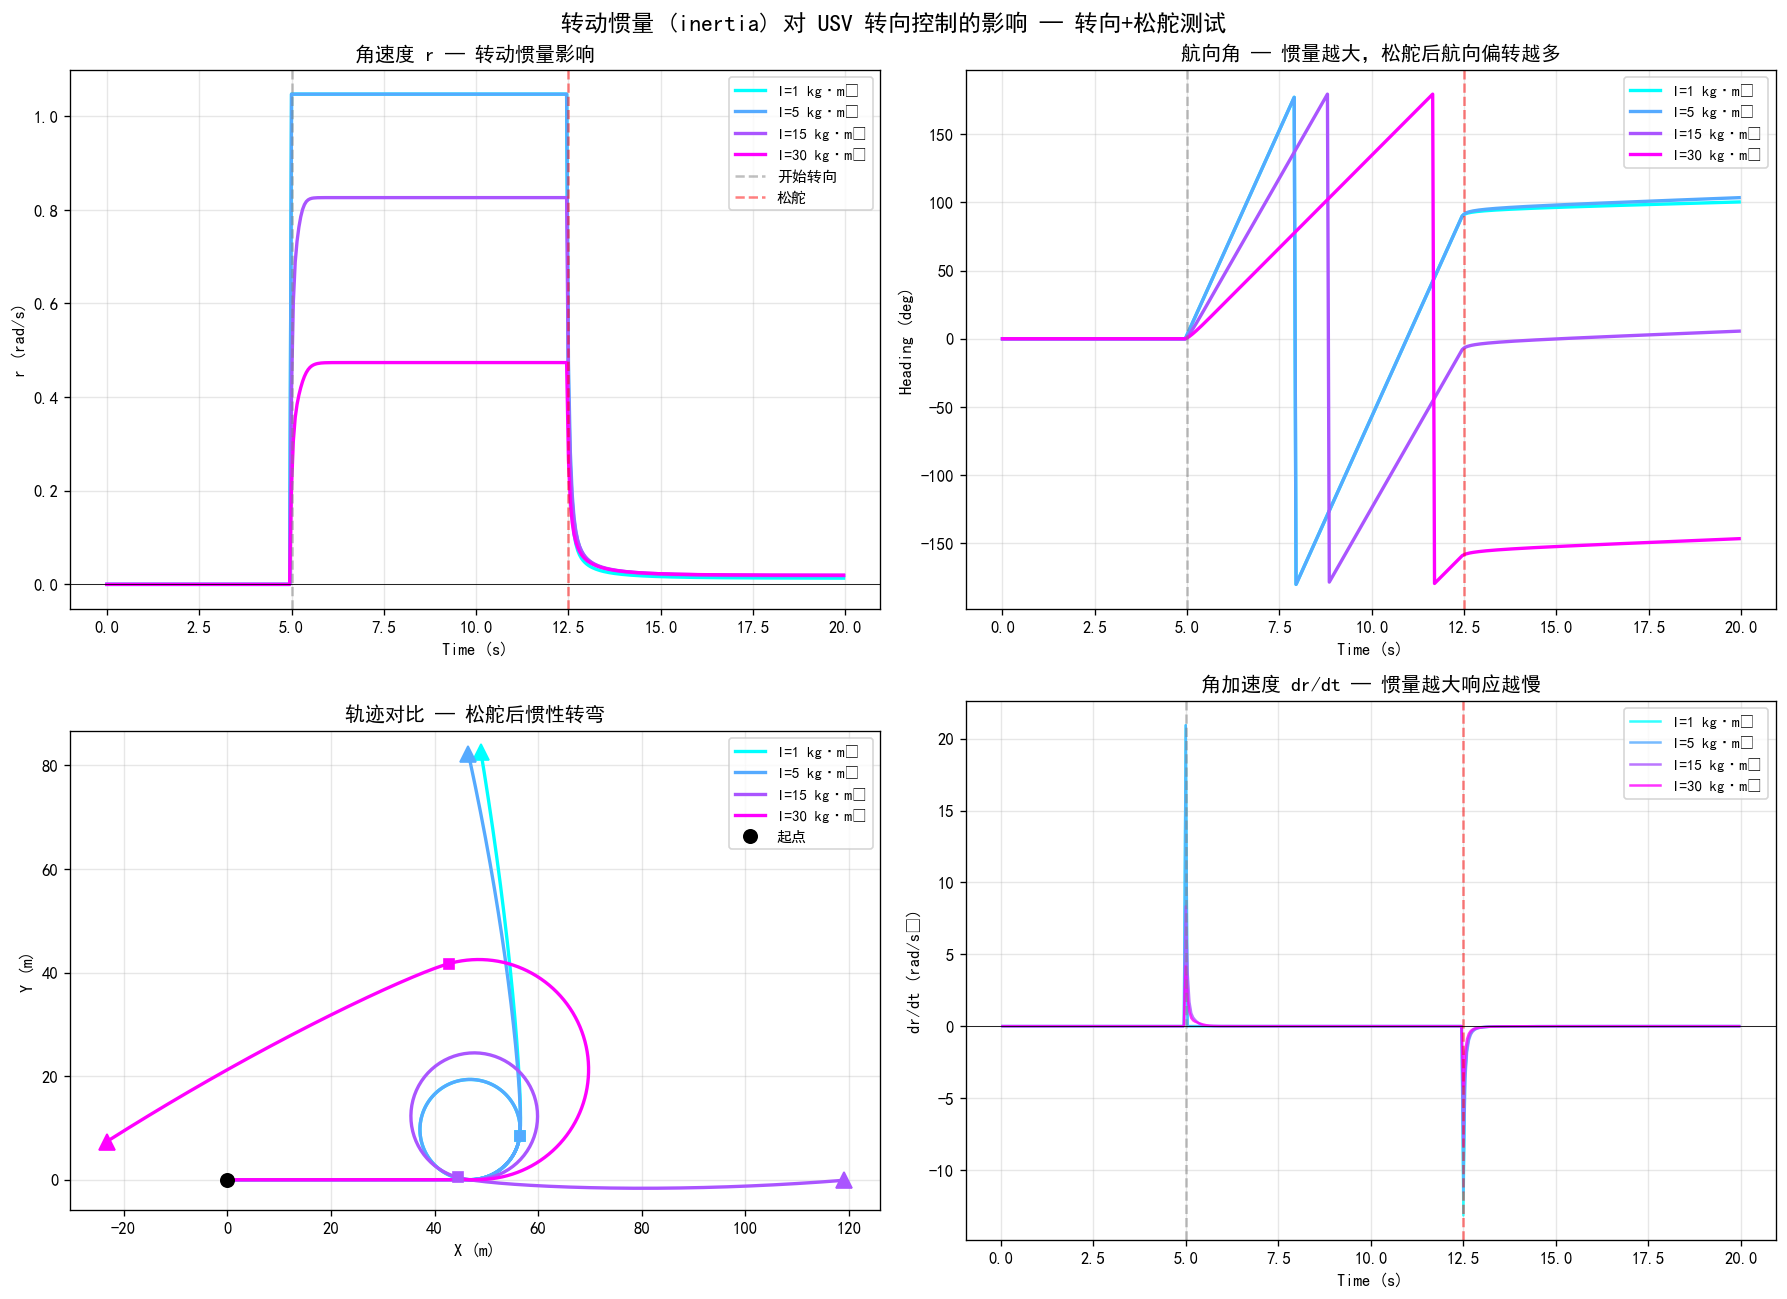

In [29]:
# ==================== 7.2 可视化: 转动惯量对转向的影响 ====================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

cmap_i = plt.cm.cool
colors_i = [cmap_i(i / (len(inertia_values) - 1)) for i in range(len(inertia_values))]

# ---- 左上: 角速度 r vs 时间 ----
ax = axes[0, 0]
for I, c in zip(inertia_values, colors_i):
    log = inertia_logs[I]
    ax.plot(log['time'], log['r'], color=c, linewidth=2, label=f'I={I} kg·m²')
ax.axvline(x=5.0, color='gray', linestyle='--', alpha=0.5, label='开始转向')
ax.axvline(x=12.5, color='red', linestyle='--', alpha=0.5, label='松舵')
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_title('角速度 r — 转动惯量影响', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('r (rad/s)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ---- 右上: 航向角 vs 时间 ----
ax = axes[0, 1]
for I, c in zip(inertia_values, colors_i):
    log = inertia_logs[I]
    ax.plot(log['time'], log['heading'], color=c, linewidth=2, label=f'I={I} kg·m²')
ax.axvline(x=5.0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=12.5, color='red', linestyle='--', alpha=0.5)
ax.set_title('航向角 — 惯量越大，松舵后航向偏转越多', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Heading (deg)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ---- 左下: 轨迹对比 ----
ax = axes[1, 0]
for I, c in zip(inertia_values, colors_i):
    log = inertia_logs[I]
    ax.plot(log['x'], log['y'], color=c, linewidth=2, label=f'I={I} kg·m²')
    ax.plot(log['x'][-1], log['y'][-1], '^', color=c, markersize=10, zorder=5)
    # 标注松舵点
    ax.plot(log['x'][250], log['y'][250], 's', color=c, markersize=6, zorder=5)
ax.plot(0, 0, 'ko', markersize=8, label='起点')
ax.set_title('轨迹对比 — 松舵后惯性转弯', fontweight='bold')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
ax.set_aspect('equal'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# ---- 右下: 角加速度 dr/dt ----
ax = axes[1, 1]
for I, c in zip(inertia_values, colors_i):
    log = inertia_logs[I]
    dr_dt = np.diff(log['r']) / 0.05
    ax.plot(log['time'][1:], dr_dt, color=c, linewidth=1.5, alpha=0.8, label=f'I={I} kg·m²')
ax.axvline(x=5.0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=12.5, color='red', linestyle='--', alpha=0.5)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_title('角加速度 dr/dt — 惯量越大响应越慢', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('dr/dt (rad/s²)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('转动惯量 (inertia) 对 USV 转向控制的影响 — 转向+松舵测试', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

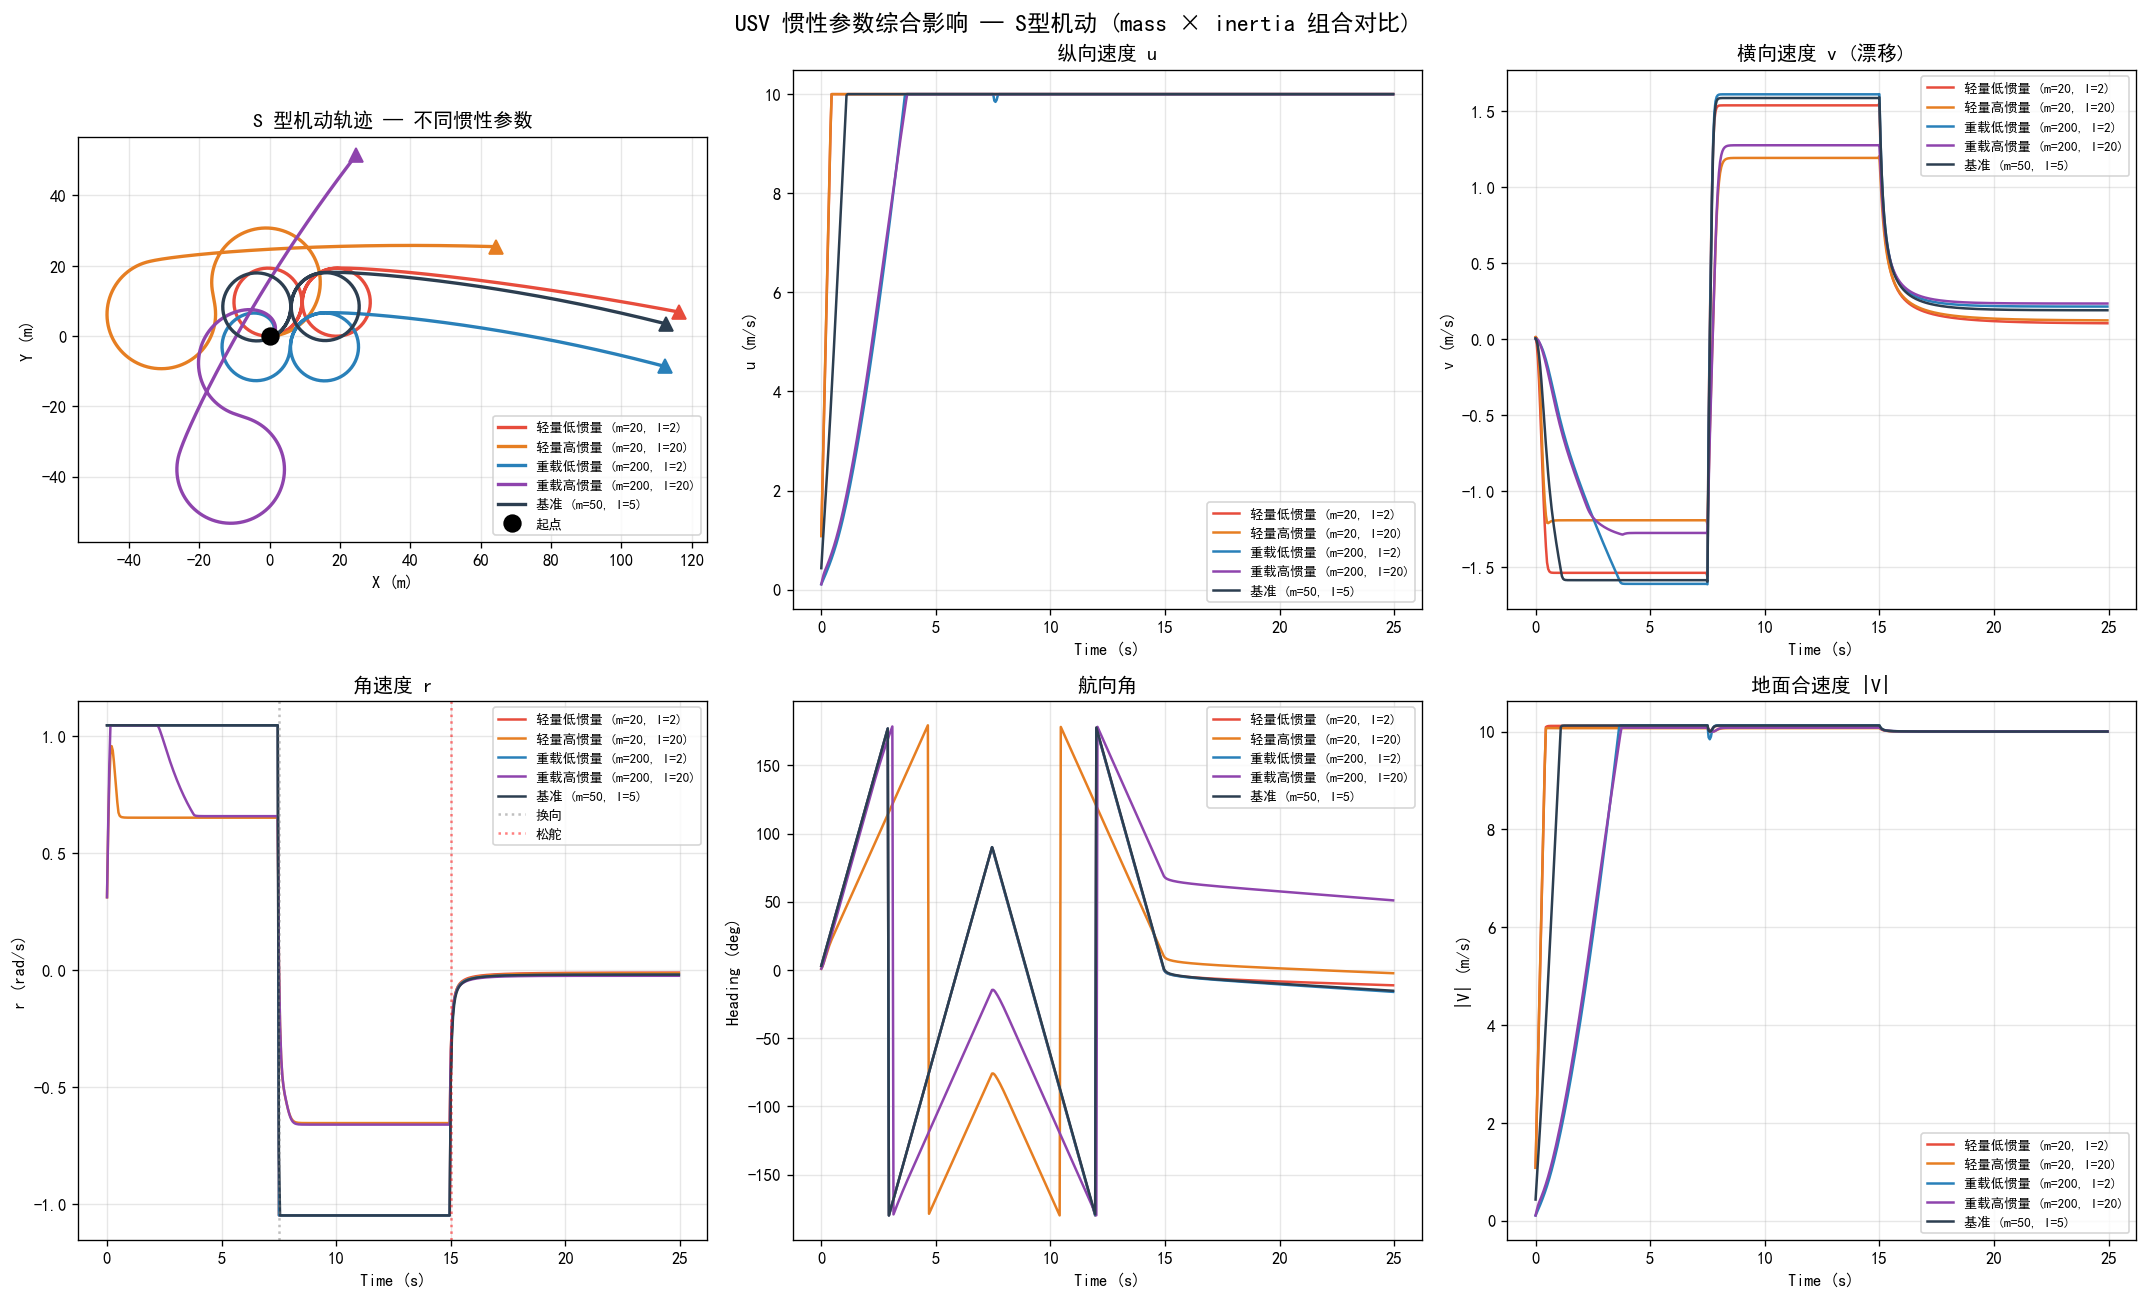

In [30]:
# ==================== 7.3 综合惯性影响 — S型机动轨迹对比 ====================
# mass × inertia 组合测试
param_combos = [
    (20,   2,  '轻量低惯量 (m=20, I=2)'),
    (20,  20,  '轻量高惯量 (m=20, I=20)'),
    (200,  2,  '重载低惯量 (m=200, I=2)'),
    (200, 20,  '重载高惯量 (m=200, I=20)'),
    (50,   5,  '基准 (m=50, I=5)'),
]

# S型机动: 前150步左转, 150-300步右转, 300+ 直行
def rudder_s_maneuver(t):
    if t < 150:
        return np.radians(30)
    elif t < 300:
        return np.radians(-30)
    else:
        return 0.0

combo_logs = {}
for m, I, label in param_combos:
    _, log = simulate_usv_inertia(
        0, 0, 0.0,
        throttle_fn=lambda t: 0.5,
        rudder_fn=rudder_s_maneuver,
        mass=m, inertia=I, steps=500)
    combo_logs[(m, I)] = (log, label)

# ---- 绘图 ----
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

combo_colors = ['#e74c3c', '#e67e22', '#2980b9', '#8e44ad', '#2c3e50']

# ---- 左上: 轨迹对比 ----
ax = axes[0, 0]
for (m, I), c in zip([k for k, _ in combo_logs.items()], combo_colors):
    log, label = combo_logs[(m, I)]
    ax.plot(log['x'], log['y'], color=c, linewidth=2, label=label)
    ax.plot(log['x'][-1], log['y'][-1], '^', color=c, markersize=8, zorder=5)
ax.plot(0, 0, 'ko', markersize=10, label='起点')
ax.set_title('S 型机动轨迹 — 不同惯性参数', fontweight='bold')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
ax.set_aspect('equal'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 右上: 纵向速度 u ----
ax = axes[0, 1]
for (m, I), c in zip([k for k, _ in combo_logs.items()], combo_colors):
    log, label = combo_logs[(m, I)]
    ax.plot(log['time'], log['u'], color=c, linewidth=1.5, label=label)
ax.set_title('纵向速度 u', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('u (m/s)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 中上: 横向速度 v ----
ax = axes[0, 2]
for (m, I), c in zip([k for k, _ in combo_logs.items()], combo_colors):
    log, label = combo_logs[(m, I)]
    ax.plot(log['time'], log['v'], color=c, linewidth=1.5, label=label)
ax.set_title('横向速度 v (漂移)', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('v (m/s)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 左下: 角速度 r ----
ax = axes[1, 0]
for (m, I), c in zip([k for k, _ in combo_logs.items()], combo_colors):
    log, label = combo_logs[(m, I)]
    ax.plot(log['time'], log['r'], color=c, linewidth=1.5, label=label)
ax.axvline(x=7.5, color='gray', linestyle=':', alpha=0.5, label='换向')
ax.axvline(x=15.0, color='red', linestyle=':', alpha=0.5, label='松舵')
ax.set_title('角速度 r', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('r (rad/s)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 中下: 航向角 ----
ax = axes[1, 1]
for (m, I), c in zip([k for k, _ in combo_logs.items()], combo_colors):
    log, label = combo_logs[(m, I)]
    ax.plot(log['time'], log['heading'], color=c, linewidth=1.5, label=label)
ax.set_title('航向角', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Heading (deg)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 右下: 地面速度 ----
ax = axes[1, 2]
for (m, I), c in zip([k for k, _ in combo_logs.items()], combo_colors):
    log, label = combo_logs[(m, I)]
    ax.plot(log['time'], log['ground_speed'], color=c, linewidth=1.5, label=label)
ax.set_title('地面合速度 |V|', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('|V| (m/s)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('USV 惯性参数综合影响 — S型机动 (mass × inertia 组合对比)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

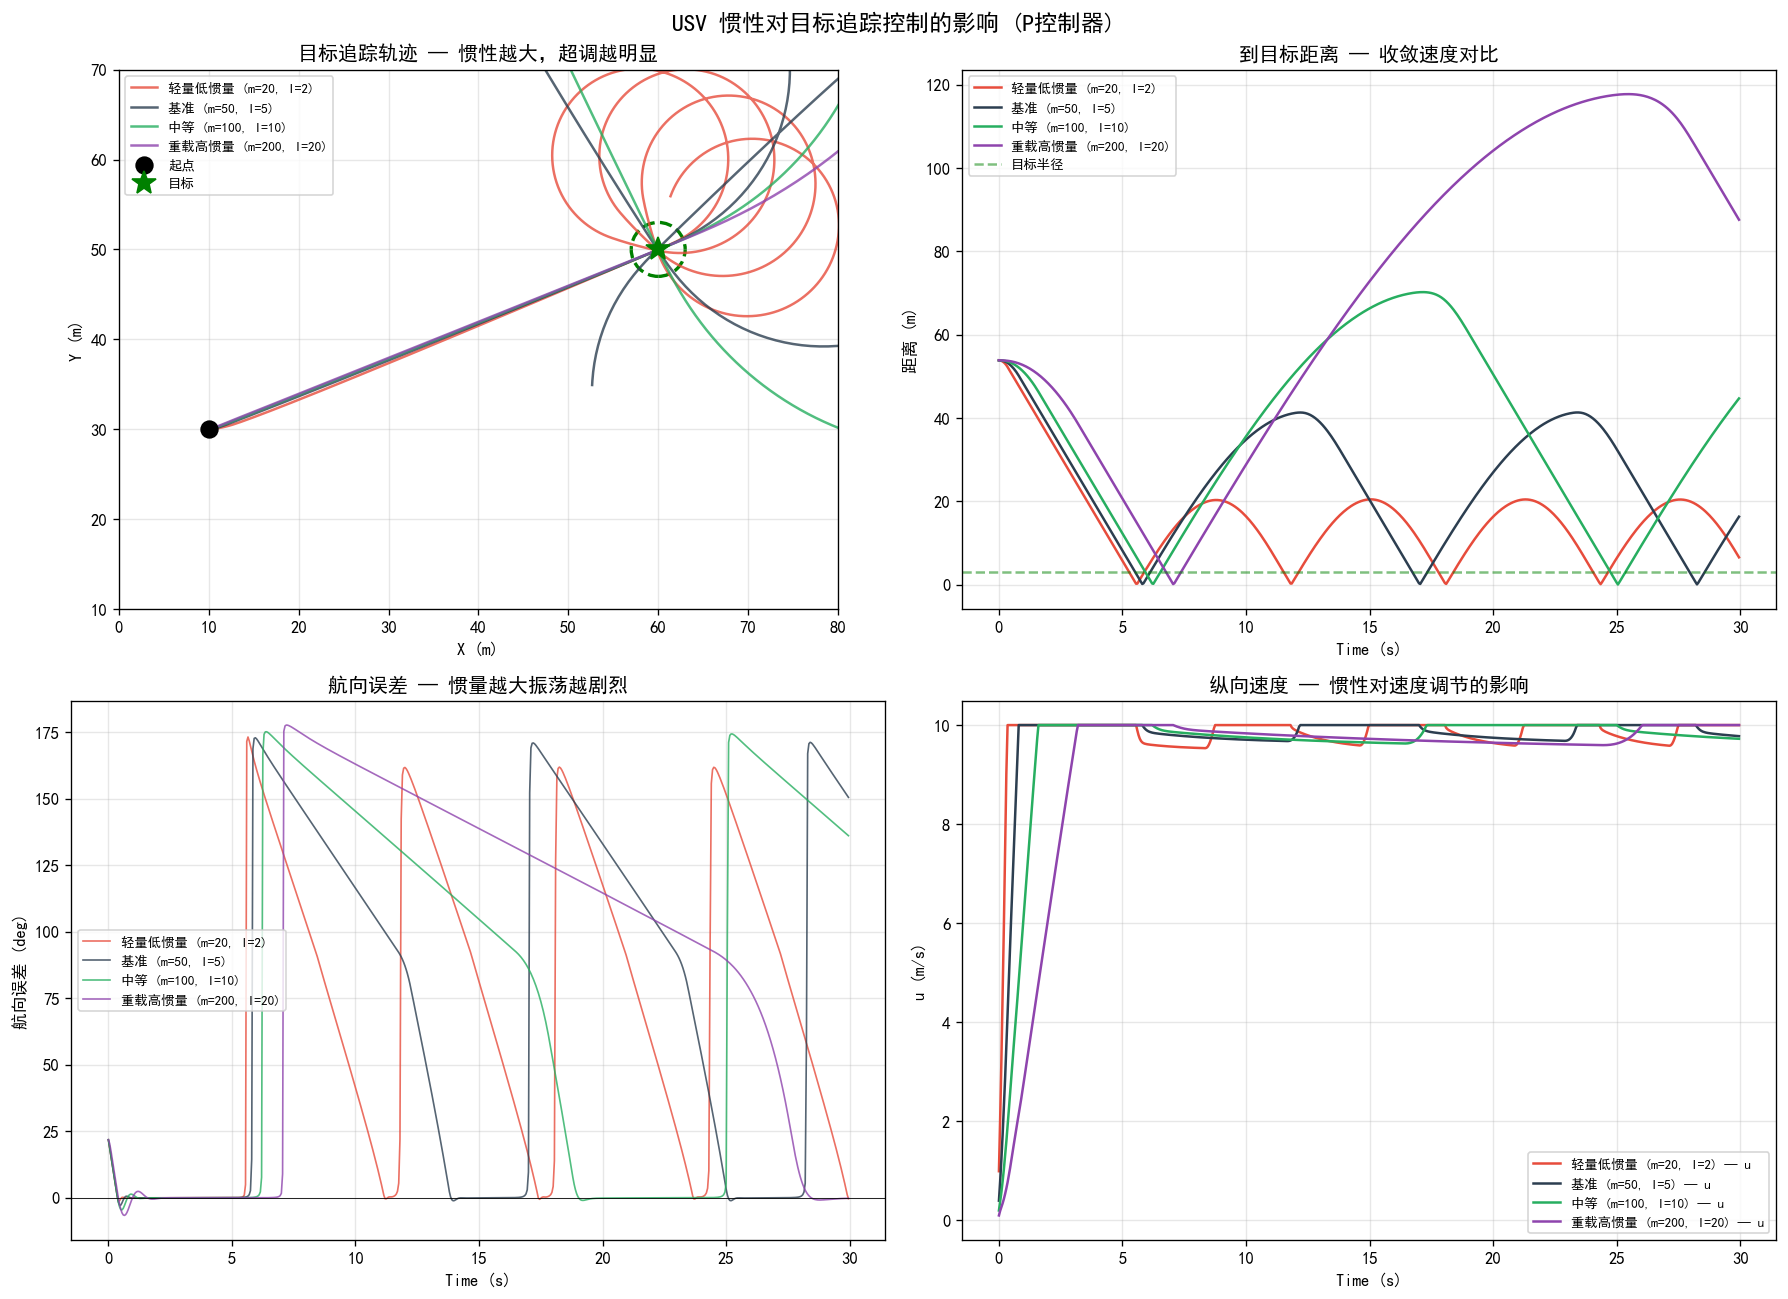


========== 惯性对目标追踪的量化影响 ==========
参数配置                               首次达到3m时间       最终距离       最大超调      航向振荡RMS
--------------------------------------------------------------------------------
  轻量低惯量 (m=20, I=2)                   5.30s      6.57m      7.45m      87.17°
  基准 (m=50, I=5)                      5.55s     16.33m     17.91m      95.02°
  中等 (m=100, I=10)                    5.95s     44.70m     32.56m     109.46°
  重载高惯量 (m=200, I=20)                 6.80s     87.58m     37.99m      80.99°


In [31]:
# ==================== 7.4 惯性对目标追踪精度的影响 ====================
# 使用P控制器追踪目标，测试不同惯性参数下的追踪精度和收敛速度

target_pos = np.array([60.0, 50.0])

param_combos_track = [
    (20,   2,  '轻量低惯量 (m=20, I=2)'),
    (50,   5,  '基准 (m=50, I=5)'),
    (100, 10,  '中等 (m=100, I=10)'),
    (200, 20,  '重载高惯量 (m=200, I=20)'),
]

track_logs = {}
for m, I, label in param_combos_track:
    usv_t = USV(x=10.0, y=30.0, heading=0.0, mass=m, inertia=I, dt=0.05)
    
    log = {'x': [usv_t.x], 'y': [usv_t.y], 'heading': [], 'u': [], 'v': [], 'r': [],
           'throttle': [], 'rudder': [], 'time': [], 'dist_to_target': [],
           'heading_error': []}
    
    for t in range(600):
        # P控制器
        dx = target_pos[0] - usv_t.x
        dy = target_pos[1] - usv_t.y
        desired_hd = np.arctan2(dy, dx)
        hd_err = desired_hd - usv_t.heading
        hd_err = (hd_err + np.pi) % (2 * np.pi) - np.pi
        
        dist = np.sqrt(dx**2 + dy**2)
        
        # 控制策略: 距离近时减速
        throttle = np.clip(0.7 - 0.4 * abs(hd_err) - max(0, (5.0 - dist)) * 0.1, 0.05, 0.8)
        rudder = np.clip(hd_err * 2.0, -1.0, 1.0)
        
        usv_t.step(throttle, rudder)
        
        log['x'].append(usv_t.x)
        log['y'].append(usv_t.y)
        log['heading'].append(np.degrees(usv_t.heading))
        log['u'].append(usv_t.u)
        log['v'].append(usv_t.v)
        log['r'].append(usv_t.r)
        log['throttle'].append(throttle)
        log['rudder'].append(np.degrees(rudder))
        log['time'].append(t * 0.05)
        log['dist_to_target'].append(dist)
        log['heading_error'].append(np.degrees(hd_err))
    
    for k in log:
        log[k] = np.array(log[k])
    track_logs[(m, I)] = (log, label)

# ---- 可视化 ----
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

track_colors = ['#e74c3c', '#2c3e50', '#27ae60', '#8e44ad']

# ---- 左上: 追踪轨迹 ----
ax = axes[0, 0]
for (m, I), c in zip([k for k, _ in track_logs.items()], track_colors):
    log, label = track_logs[(m, I)]
    ax.plot(log['x'], log['y'], color=c, linewidth=1.5, label=label, alpha=0.8)
ax.plot(10.0, 30.0, 'ko', markersize=10, label='起点', zorder=6)
target_circle = plt.Circle(target_pos, 3.0, color='green', fill=False, linestyle='--', linewidth=2)
ax.add_patch(target_circle)
ax.plot(target_pos[0], target_pos[1], 'g*', markersize=15, zorder=6, label='目标')
ax.set_title('目标追踪轨迹 — 惯性越大，超调越明显', fontweight='bold')
ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)')
ax.set_aspect('equal'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
ax.set_xlim(0, 80); ax.set_ylim(10, 70)

# ---- 右上: 到目标距离 vs 时间 ----
ax = axes[0, 1]
for (m, I), c in zip([k for k, _ in track_logs.items()], track_colors):
    log, label = track_logs[(m, I)]
    ax.plot(log['time'], log['dist_to_target'], color=c, linewidth=1.5, label=label)
ax.axhline(y=3.0, color='green', linestyle='--', alpha=0.5, label='目标半径')
ax.set_title('到目标距离 — 收敛速度对比', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('距离 (m)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 左下: 航向误差 vs 时间 ----
ax = axes[1, 0]
for (m, I), c in zip([k for k, _ in track_logs.items()], track_colors):
    log, label = track_logs[(m, I)]
    ax.plot(log['time'], log['heading_error'], color=c, linewidth=1, alpha=0.8, label=label)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_title('航向误差 — 惯量越大振荡越剧烈', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('航向误差 (deg)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ---- 右下: 控制输入对比 ----
ax = axes[1, 1]
for (m, I), c in zip([k for k, _ in track_logs.items()], track_colors):
    log, label = track_logs[(m, I)]
    ax.plot(log['time'], log['u'], color=c, linewidth=1.5, label=f'{label} — u')
ax.set_title('纵向速度 — 惯性对速度调节的影响', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('u (m/s)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('USV 惯性对目标追踪控制的影响 (P控制器)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 打印量化对比
print("\n========== 惯性对目标追踪的量化影响 ==========")
print(f"{'参数配置':<28s} {'首次达到3m时间':>14s} {'最终距离':>10s} {'最大超调':>10s} {'航向振荡RMS':>12s}")
print("-" * 80)
for (m, I), c in zip([k for k, _ in track_logs.items()], track_colors):
    log, label = track_logs[(m, I)]
    # 首次达到3m距离的时间
    reach_idx = np.where(log['dist_to_target'] <= 3.0)[0]
    reach_time = log['time'][reach_idx[0]] if len(reach_idx) > 0 else -1
    final_dist = log['dist_to_target'][-1]
    # 到达目标附近后的距离振荡
    if len(reach_idx) > 0:
        overshoot = np.min(log['dist_to_target'][reach_idx[0]:]) 
        # 到达后的最远距离作为超调量
        post_reach = log['dist_to_target'][reach_idx[0]:]
        max_overshoot = np.max(post_reach) - np.mean(post_reach)
    else:
        max_overshoot = -1
    hd_rms = np.sqrt(np.mean(log['heading_error'][-200:]**2))
    
    rt_str = f"{reach_time:.2f}s" if reach_time > 0 else "未达到"
    os_str = f"{max_overshoot:.2f}m" if max_overshoot >= 0 else "N/A"
    print(f"  {label:<26s} {rt_str:>14s} {final_dist:>9.2f}m {os_str:>10s} {hd_rms:>10.2f}°")